In [1]:
#from google.colab import drive
#drive.mount('/content/drive')

from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\Alex\Desktop\programas\tesis")
METADATA_DIR = PROJECT_DIR

print(f"Proyecto: {PROJECT_DIR}")
print(f"Metadatos: {METADATA_DIR / 'hmp2_metadata_2018-08-20.csv'}")

Proyecto: C:\Users\Alex\Desktop\programas\tesis
Metadatos: C:\Users\Alex\Desktop\programas\tesis\hmp2_metadata_2018-08-20.csv


### Reading `hmp2_metadata_2018-08-20.csv`

In [2]:
import pandas as pd

csv_file_path = METADATA_DIR / "hmp2_metadata_2018-08-20.csv"

if not csv_file_path.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo:\n  {csv_file_path}\n\n"
        f"Copia hmp2_metadata_2018-08-20.csv a {METADATA_DIR} o actualiza METADATA_DIR en la celda anterior."
    )

df_csv = pd.read_csv(csv_file_path, low_memory=False)
print(f"Successfully loaded {csv_file_path}")
display(df_csv.head())

Successfully loaded C:\Users\Alex\Desktop\programas\tesis\hmp2_metadata_2018-08-20.csv


,Project,External ID,Participant ID,site_sub_coll,data_type,week_num,date_of_receipt,interval_days,visit_num,Research Project,...,FecalCal received at MGH:,Proteomics received at LBNL:,Stool Sample ID: Tube A (EtOH),Sample ID: Tube B (No preservative),Tube A and B received at Broad:,stool_id,smoking status,Number years smoked,Age when started smoking,How many cigarettes/cigars/etc. do you smoke per day?
0,C3001CSC1_BP,206615,C3001,C3001CSC1,biopsy_16S,2.0,NaN,NaN,1,ibdmdb,...,No,No,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN
1,C3001CSC2_BP,206614,C3001,C3001CSC2,biopsy_16S,2.0,NaN,NaN,1,ibdmdb,...,No,No,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN
2,C3002CSC1_BP,206617,C3002,C3002CSC1,biopsy_16S,0.0,NaN,NaN,1,ibdmdb,...,No,No,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN
3,C3002CSC2_BP,206619,C3002,C3002CSC2,biopsy_16S,0.0,NaN,NaN,1,ibdmdb,...,No,No,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN
4,C3002CSC3_BP,206616,C3002,C3002CSC3,biopsy_16S,0.0,NaN,NaN,1,ibdmdb,...,No,No,NaN,NaN,No,NaN,NaN,NaN,NaN,NaN


### Detailed Review of Columns (No Deletion)

In [3]:
# Get all object type columns that are not constant
non_constant_object_columns = [col for col in df_csv.select_dtypes(include='object').columns if df_csv[col].nunique(dropna=False) > 1]

print(f"Number of non-constant object columns: {len(non_constant_object_columns)}")
print("Here are the first 20 non-constant object columns (out of {}"
      "- you can expand this list if needed):\n".format(len(non_constant_object_columns)))
for i, col in enumerate(non_constant_object_columns[:20]):
    print(f"{i+1}. {col}")

# You can choose a column from the list above to inspect its unique values
selected_object_column = 'data_type' # @param {type:"string"}

if selected_object_column in df_csv.columns and df_csv[selected_object_column].dtype == 'object':
    print(f"\nUnique values and their counts for '{selected_object_column}':")
    display(df_csv[selected_object_column].value_counts(dropna=False))
else:
    print(f"\n'{selected_object_column}' is not a valid object column or does not exist.")

Number of non-constant object columns: 358
Here are the first 20 non-constant object columns (out of 358- you can expand this list if needed):

1. Project
2. External ID
3. Participant ID
4. site_sub_coll
5. data_type
6. date_of_receipt
7. PDO Number
8. Product
9. LCSET
10. Aggregated Lanes
11. IntervalName
12. site_name
13. Has the subject had a cholecystectomy?
14. Has the subject had a prior abdominal surgery (other)?
15. Has the next visit been scheduled?
16. Has the subject been given new stool kits?
17. Has the subject completed the FFQ/YAQ?
18. Education Level
19. Occupation
20. Scanned FFQ/YAQ document:

'data_type' is not a valid object column or does not exist.


C:\Users\Alex\AppData\Local\Temp\ipykernel_11244\1191688686.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  non_constant_object_columns = [col for col in df_csv.select_dtypes(include='object').columns if df_csv[col].nunique(dropna=False) > 1]


Number of non-empty numerical columns (more than 10% non-missing): 22
Here are the first 20 non-empty numerical columns (out of 22- you can expand this list if needed):

1. week_num
2. interval_days
3. visit_num
4. reads_raw
5. reads_filtered
6. reads_qc_fail
7. reads_human
8. reads_ribosomal
9. reads_viral
10. IntervalSequence
11. ProjectSpecificID
12. Age at diagnosis
13. Number of flora tubes collected:
14. Rectum Flora:
15. Number of DNA/RNA tubes collected:
16. consent_age
17. Number of liquid or very soft stools in the past 24 hours:
18. hbi
19. CRP (mg/L)
20. ESR (mm/hr)

Distribution for 'week_num':


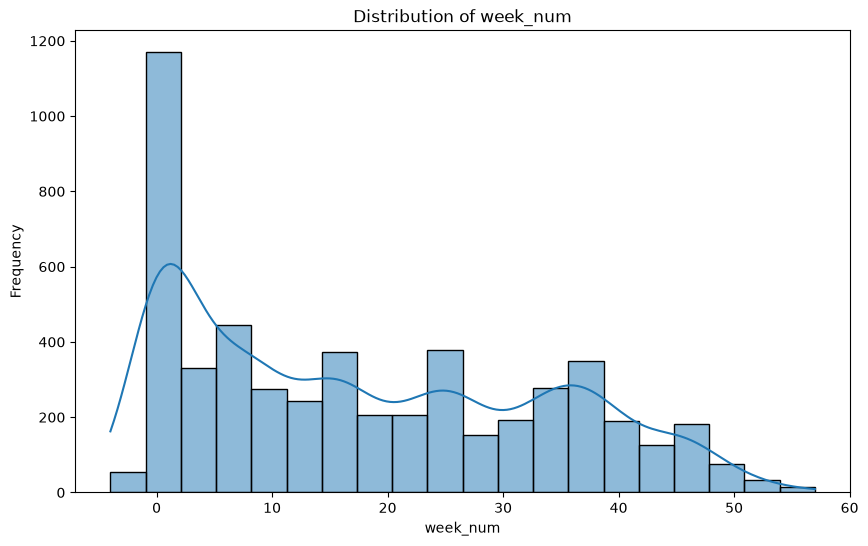

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Get all numerical type columns that are not almost empty (e.g., >10% non-missing)
non_empty_numerical_columns = [col for col in df_csv.select_dtypes(include=['int64', 'float64']).columns if df_csv[col].count() / len(df_csv) > 0.1]

print(f"Number of non-empty numerical columns (more than 10% non-missing): {len(non_empty_numerical_columns)}")
print("Here are the first 20 non-empty numerical columns (out of {}"
      "- you can expand this list if needed):\n".format(len(non_empty_numerical_columns)))
for i, col in enumerate(non_empty_numerical_columns[:20]):
    print(f"{i+1}. {col}")

# You can choose a column from the list above to visualize its distribution
selected_numerical_column = 'week_num' # @param {type:"string"}

if selected_numerical_column in df_csv.columns and df_csv[selected_numerical_column].dtype in ['int64', 'float64']:
    print(f"\nDistribution for '{selected_numerical_column}':")
    plt.figure(figsize=(10, 6))
    sns.histplot(df_csv[selected_numerical_column].dropna(), kde=True)
    plt.title(f'Distribution of {selected_numerical_column}')
    plt.xlabel(selected_numerical_column)
    plt.ylabel('Frequency')
    plt.show()
else:
    print(f"\n'{selected_numerical_column}' is not a valid numerical column or does not exist.")

In [5]:
cross = pd.crosstab(
    df_csv['External ID'],
    df_csv['data_type']
)

cross.head()

data_type,biopsy_16S,host_genome,host_transcriptomics,metabolomics,metagenomics,metatranscriptomics,methylome,proteomics,serology,stool_16S,viromics
External ID,,,,,,,,,,,
206454,0,0,0,0,0,0,0,0,1,0,0
206458,0,0,0,0,0,0,0,0,1,0,0
206459,0,0,0,0,0,0,0,0,1,0,0
206460,0,0,0,0,0,0,0,0,1,0,0
206461,0,0,0,0,0,0,0,0,1,0,0


In [6]:
required = [
    'metagenomics',
    'metatranscriptomics',
    'metabolomics'
]

complete_samples = cross[
    (cross[required] > 0).all(axis=1)
]

print(len(complete_samples))

306


In [7]:
ids = complete_samples.index

subset = df_csv[
    df_csv['External ID'].isin(ids)
]

subset['Participant ID'].nunique()

100

In [8]:
subset.groupby('Participant ID')['External ID'].nunique().sort_values(ascending=False)

Participant ID
C3027    6
M2061    6
M2084    6
H4035    6
M2069    6
        ..
M2026    1
M2072    1
M2060    1
P6014    1
P6017    1
Name: External ID, Length: 100, dtype: int64

In [9]:
print(df_csv.columns.tolist())

['Project', 'External ID', 'Participant ID', 'site_sub_coll', 'data_type', 'week_num', 'date_of_receipt', 'interval_days', 'visit_num', 'Research Project', 'PDO Number', 'GSSR IDs', 'Product', 'LCSET', 'Aggregated Lanes', 'WR ID', '# Lanes in Aggregation', 'reads_raw', 'reads_filtered', 'reads_qc_fail', 'reads_human', 'reads_ribosomal', 'reads_viral', 'Delta', 'IntervalName', 'IntervalSequence', 'ProjectSpecificID', 'site_name', 'Age at diagnosis', 'Has the subject had a cholecystectomy?', 'Has the subject had a prior abdominal surgery (other)?', 'Has the next visit been scheduled?', 'Has the subject been given new stool kits?', 'Has the subject completed the FFQ/YAQ?', 'Education Level', 'Occupation', 'Scanned FFQ/YAQ document:', 'FFQ/YAQ results:', 'Has the subject had an appendectomy?', 'Has the subject had a tonsillectomy?', 'biopsy_location', 'Were study bloods drawn?', 'Whole blood received at Broad:', 'Serum tube #1 received at CSMC:', 'Serum tubes #2-4 received at MGH:', 'Whole

In [10]:
omics = df_csv[
    df_csv["data_type"].isin([
        "metagenomics",
        "metatranscriptomics",
        "metabolomics"
    ])
]

omics.shape

(3019, 490)

In [11]:
pd.crosstab(
    df_csv["External ID"],
    df_csv["data_type"]
).head()

data_type,biopsy_16S,host_genome,host_transcriptomics,metabolomics,metagenomics,metatranscriptomics,methylome,proteomics,serology,stool_16S,viromics
External ID,,,,,,,,,,,
206454,0,0,0,0,0,0,0,0,1,0,0
206458,0,0,0,0,0,0,0,0,1,0,0
206459,0,0,0,0,0,0,0,0,1,0,0
206460,0,0,0,0,0,0,0,0,1,0,0
206461,0,0,0,0,0,0,0,0,1,0,0


In [12]:
df_csv.groupby(
    ["Participant ID", "week_num"]
)["data_type"].unique()

Participant ID  week_num
C3001           0.0         [metabolomics, metagenomics, proteomics, stool...
                2.0                     [biopsy_16S, metagenomics, stool_16S]
                4.0                                 [metagenomics, stool_16S]
                6.0                                 [metagenomics, stool_16S]
                8.0         [metabolomics, metagenomics, metatranscriptomi...
                                                  ...                        
P6038           24.0                                           [metagenomics]
                26.0        [metabolomics, metagenomics, metatranscriptomi...
                34.0                                           [metagenomics]
                35.0                                           [metagenomics]
                37.0        [metabolomics, metagenomics, metatranscriptomi...
Name: data_type, Length: 1956, dtype: object

In [13]:
cross = pd.crosstab(
    [df_csv["Participant ID"],
     df_csv["week_num"]],
    df_csv["data_type"]
)

required = [
    "metagenomics",
    "metatranscriptomics",
    "metabolomics"
]

complete = cross[
    (cross[required] > 0).all(axis=1)
]

print("Observaciones completas:", len(complete))

Observaciones completas: 332


In [14]:
cross = pd.crosstab(
    [df_csv['Participant ID'],
     df_csv['week_num']],
    df_csv['data_type']
)

cross = (cross > 0).astype(int)

In [15]:
omics = [
    'metagenomics',
    'metatranscriptomics',
    'metabolomics',
    'proteomics',
    'viromics',
    'methylome',
    'host_transcriptomics',
    'serology'
]

for omic in omics:
    n = (
        (cross['metagenomics'] == 1) &
        (cross['metatranscriptomics'] == 1) &
        (cross['metabolomics'] == 1) &
        (cross[omic] == 1)
    ).sum()

    print(omic, n)

metagenomics 332
metatranscriptomics 332
metabolomics 332
proteomics 181
viromics 291
methylome 19
host_transcriptomics 12
serology 10


## analisis de la base de datos


In [16]:
import os

base_directory = PROJECT_DIR

print(f"Listing contents of: {base_directory}\n")

for root, dirs, files in os.walk(base_directory):
    # Print current directory
    print(f"Directory: {root}")

    # Print subdirectories
    if dirs:
        print("  Subdirectories:")
        for d in dirs:
            print(f"    - {d}")
    else:
        print("  No subdirectories.")

    # Print files
    if files:
        print("  Files:")
        for f in files:
            print(f"    - {f}")
    else:
        print("  No files.")
    print("\n")

Listing contents of: C:\Users\Alex\Desktop\programas\tesis

Directory: C:\Users\Alex\Desktop\programas\tesis
  Subdirectories:
    - intentos
    - Metabolomics (MBX)
    - Metagenomics (MGX)
    - Metatranscriptomics (MTX)
    - Viromics
  Files:
    - analisis_base_datos_IBDMDB.ipynb
    - DeteccionOutlier.pdf
    - hmp2_metadata_2018-08-20.csv


Directory: C:\Users\Alex\Desktop\programas\tesis\intentos
  No subdirectories.
  Files:
    - analisis_base_datos_IBDMDB 2.ipynb


Directory: C:\Users\Alex\Desktop\programas\tesis\Metabolomics (MBX)
  No subdirectories.
  Files:
    - C18n_Metabolites_ID_AfterPublication_2021-05-17.xlsx
    - HMP2_metabolomics_w_metadata.biom.gz


Directory: C:\Users\Alex\Desktop\programas\tesis\Metagenomics (MGX)
  No subdirectories.
  Files:
    - ecs_relab.tsv.gz
    - pathabundance_relab.tsv.gz
    - taxonomic_profiles.tsv.gz


Directory: C:\Users\Alex\Desktop\programas\tesis\Metatranscriptomics (MTX)
  No subdirectories.
  Files:
    - ecs_relab.tsv.gz


### Carpeta: `Metabolomics (MBX)`
### Archivo: `C18n_Metabolites_ID_AfterPublication_2021-05-17.xlsx`

In [17]:
import pandas as pd

df = pd.read_excel(PROJECT_DIR / "Metabolomics (MBX)" / "C18n_Metabolites_ID_AfterPublication_2021-05-17.xlsx")
df.head()

,Method,Compound,m/z,RT (min),Metabolite identified after publication
0,C18n,QI1629,213.1854,12.70,11-methyl laurate
1,C18n,QI3732,295.2279,11.21,13-HODE
2,C18n,QI2118,239.2014,13.31,14-pentadecenoic acid
3,C18n,QI6169,373.2749,12.20,3-oxo lithocholic acid
4,C18n,QI6172,373.2749,12.35,3-oxolithocholate


### Carpeta: `Metabolomics (MBX)`
### Archivo: `HMP2_metabolomics_w_metadata.biom.gz`

In [18]:
import biom

tabla = biom.load_table(str(PROJECT_DIR / "Metabolomics (MBX)" / "HMP2_metabolomics_w_metadata.biom.gz"))
muestras = tabla.ids(axis="sample")[:5]
metabolitos = tabla.ids(axis="observation")[:5]
sub = tabla.filter(muestras, axis="sample").filter(metabolitos, axis="observation")
sub.to_dataframe(dense=True)

,HSM5FZBJ,MSM5FZ9X,CSM5FZ3N,ESM5MEDZ,MSM5FZA2
C18n_QI06,4355470.0,2623839.0,942546.0,5759125.0,2231416.0
C18n_QI07,1512589.0,2299190.0,1418451.0,3515867.0,1589344.0
C18n_QI08,9636.0,100.0,2194.0,161.0,962.0
C18n_QI09,0.0,0.0,0.0,0.0,0.0
C18n_QI10,40871.0,8382.0,38180.0,58551.0,5542.0


### Carpeta: `Metagenomics (MGX)`
### Archivo: `ecs_relab.tsv.gz`

In [19]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Metagenomics (MGX)" / "ecs_relab.tsv.gz", sep="\t", nrows=5)
df.head()

,# Gene Family,CSM5FZ4M,CSM5MCUO,CSM5MCVL,CSM5MCVN,CSM5MCW6,CSM5MCWC,CSM5MCWE,CSM5MCWG,CSM5MCWQ,...,CSM5MCVJ_P,CSM5MCWI_P,MSM5LLHA_P,HSM5MD59_P,HSM5MD8N_P,CSM6J2H9_P,HSM5MD4A_P,CSM5MCUW_P,ESM5MEBA_P,HSM5FZC2_P
0,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.001835,0.001472,0.001571,0.001173,0.000247,0.002389,0.000922,0.000573,0.001827,...,0.001729,0.001808,0.000637,0.001905,0.001688,0.001838,0.001919,0.001391,0.001247,0.000429
1,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


### Carpeta: `Metagenomics (MGX)`
### Archivo: `pathabundance_relab.tsv.gz`

In [20]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Metagenomics (MGX)" / "pathabundance_relab.tsv.gz", sep="\t", nrows=5)
df.head()

,# Pathway,CSM5FZ4M,CSM5MCUO,CSM5MCVL,CSM5MCVN,CSM5MCW6,CSM5MCWC,CSM5MCWE,CSM5MCWG,CSM5MCWQ,...,CSM5MCVJ_P,CSM5MCWI_P,MSM5LLHA_P,HSM5MD59_P,HSM5MD8N_P,CSM6J2H9_P,HSM5MD4A_P,CSM5MCUW_P,ESM5MEBA_P,HSM5FZC2_P
0,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.01581,0.010170,0.016743,0.018002,0.015312,0.004618,0.004357,0.003774,0.011898,...,0.019465,0.022263,0.008464,0.009967,0.013779,0.011970,0.006240,0.010508,0.013684,0.016919
1,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000026,0.000000,0.000000,0.001087,0.000000,0.000386,0.000000,0.000000,0.000000
2,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.00000,0.000157,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000496,0.000070,0.000210,0.000469,0.000113,0.000000,0.000000,0.000000,0.000000
4,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000104,0.000000,0.000145,0.000000,0.000000


### Carpeta: `Metagenomics (MGX)`
### Archivo: `taxonomic_profiles.tsv.gz`

In [21]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Metagenomics (MGX)" / "taxonomic_profiles.tsv.gz", sep="\t", nrows=5)
df.head()

,#SampleID,CSM5FZ4M,CSM5MCUO,CSM5MCVL,CSM5MCVN,CSM5MCW6,CSM5MCWC,CSM5MCWE,CSM5MCWG,CSM5MCWQ,...,CSM5MCVJ_P,CSM5MCWI_P,MSM5LLHA_P,HSM5MD59_P,HSM5MD8N_P,CSM6J2H9_P,HSM5MD4A_P,CSM5MCUW_P,ESM5MEBA_P,HSM5FZC2_P
0,k__Archaea,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0.000093,0,0
1,k__Archaea|p__Euryarchaeota,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0.000093,0,0
2,k__Archaea|p__Euryarchaeota|c__Methanobacteria,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0.000093,0,0
3,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0.000093,0,0
4,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0.000093,0,0


### Carpeta: `Metatranscriptomics (MTX)`
### Archivo: `ecs_relab.tsv.gz`

In [22]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Metatranscriptomics (MTX)" / "ecs_relab.tsv.gz", sep="\t", nrows=5)
df.head()

,# Gene Family,CSM5FZ4M,CSM5MCUO,CSM5MCVN,CSM5MCW6,CSM5MCWC,CSM5MCWE,CSM5MCWQ,CSM5MCX3,CSM5MCXD,...,MSMB4LZ4,PSM6XBRK_TR,PSM6XBSM,PSM6XBUQ,PSM6XBV4,PSM7J12D,PSM7J171,PSMA265J_TR,PSMA265J,PSMA266U
0,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.003216,0.001697,0.002806,0.000035,0.00077,0.000931,0.001475,0.002191,0.004557,...,0.001202,0.003518,0.001,0.000725,0.001939,0.002268,0.001292,0.000198,0.000205,0.000719
1,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000002,0.000000,...,0.000009,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000064
3,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000070,...,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000260,0.000000,0.000000,0.00000,0.000000,0.000000,0.000133,0.000238,...,0.000108,0.000000,0.000,0.000000,0.000000,0.000657,0.000151,0.000000,0.000000,0.000000


### Carpeta: `Metatranscriptomics (MTX)`
### Archivo: `genefamilies (1).tsv.gz`

In [23]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Metatranscriptomics (MTX)" / "genefamilies (1).tsv.gz", sep="\t", nrows=5, low_memory=False)
df.head()

,# Gene Family,CSM5FZ4M_Abundance-RPKs,CSM5MCUO_Abundance-RPKs,CSM5MCVN_Abundance-RPKs,CSM5MCW6_Abundance-RPKs,CSM5MCWC_Abundance-RPKs,CSM5MCWE_Abundance-RPKs,CSM5MCWQ_Abundance-RPKs,CSM5MCX3_Abundance-RPKs,CSM5MCXD_Abundance-RPKs,...,PSMA267R_Abundance-RPKs,PSMA269G_Abundance-RPKs,PSMA269O_Abundance-RPKs,PSMA269S_Abundance-RPKs,PSMA269W_Abundance-RPKs,PSMA26A3_Abundance-RPKs,PSMB4MBK_Abundance-RPKs,PSMB4MBS_Abundance-RPKs,PSMB4MC5_Abundance-RPKs,PSMB4MC7_Abundance-RPKs
0,UniRef90_A0A009DJS4,0,0,0,0,0,0.000000e+00,0,0,0,...,0,0.000000,0,0,0,0,0,0,0,0
1,UniRef90_A0A009DJS4|unclassified,0,0,0,0,0,0.000000e+00,0,0,0,...,0,0.000000,0,0,0,0,0,0,0,0
2,UniRef90_A0A009DPX5,0,0,0,0,0,0.000000e+00,0,0,0,...,0,0.000000,0,0,0,0,0,0,0,0
3,UniRef90_A0A009DPX5|g__Escherichia.s__Escheric...,0,0,0,0,0,0.000000e+00,0,0,0,...,0,0.000000,0,0,0,0,0,0,0,0
4,UniRef90_A0A009DU02,0,0,0,0,0,8.958070e-07,0,0,0,...,0,0.000001,0,0,0,0,0,0,0,0


### Carpeta: `Metatranscriptomics (MTX)`
### Archivo: `pathabundance_relab.tsv.gz`

In [24]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Metatranscriptomics (MTX)" / "pathabundance_relab.tsv.gz", sep="\t", nrows=5)
df.head()

,# Pathway,CSM5FZ4M,CSM5MCUO,CSM5MCVN,CSM5MCW6,CSM5MCWC,CSM5MCWE,CSM5MCWQ,CSM5MCX3,CSM5MCXD,...,MSMB4LZ4,PSM6XBRK_TR,PSM6XBSM,PSM6XBUQ,PSM6XBV4,PSM7J12D,PSM7J171,PSMA265J_TR,PSMA265J,PSMA266U
0,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.015748,0.007513,0.025239,0.017006,0.002012,0.002018,0.015234,0.010873,0.023642,...,0.007144,0.01399,0.005663,0.007099,0.014726,0.013905,0.006449,0,0.000855,0.004999
1,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0.000000
2,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0.000000
3,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000057,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0.000000
4,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0,0.000000,0.000000


### Carpeta: `Viromics`
### Archivo: `taxonomic_profiles.tsv.gz`

In [25]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Viromics" / "taxonomic_profiles.tsv.gz", sep="\t", nrows=5)
df.head()

,#ID,CSM5MCXD,MSM5LLEP,MSM5LLDC,CSM5MCXH,MSM6J2J3,MSM5LLHC,HSM5MD5D,HSM5MD62,ESM5MEDN,...,HSMA33RT,CSM9X23P,PSMB4MBS,PSMB4MC7,HSMA33SG,HSMA33SI,MSMB4LZX,MSMB4LZ4,HSMA33RX,MSMB4LYB
0,k__Viruses|p__Viruses_noname|c__Viruses_noname...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00000,0.0,0.00000,0.0,0.0,0.0,0.0
1,k__Viruses|p__Viruses_noname|c__Viruses_noname...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00000,0.0,0.00000,0.0,0.0,0.0,0.0
2,k__Viruses|p__Viruses_noname|c__Viruses_noname...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00000,0.0,0.00000,0.0,0.0,0.0,0.0
3,k__Viruses|p__Viruses_noname|c__Viruses_noname...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.00000,0.0,0.00000,0.0,0.0,0.0,0.0
4,k__Viruses|p__Viruses_noname|c__Viruses_noname...,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.06046,100.0,11.20647,0.0,0.0,100.0,0.0


### Carpeta: `Viromics`
### Archivo: `virome_virmap_analysis.tsv.gz`

In [26]:
import pandas as pd

df = pd.read_csv(PROJECT_DIR / "Viromics" / "virome_virmap_analysis.tsv.gz", sep="\t", nrows=5)
df.head()

,Virus,MSM5LLDS,CSM5FZ4M,HSM5FZBZ,HSM5MD5B,CSM5MCXD,CSM5MCUO,MSM6J2IE,ESM5MEBS,MSM5LLEP,...,HSMA33SI,MSMB4LZC,MSMB4LZR,MSMB4LZ8,HSMA33SK,MSMB4LYH,PSMB4MC5,HSMA33RX,MSMB4LYB,MSMB4LZK
0,"superkingdom=Viruses;dsDNA viruses, no RNA sta...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,"superkingdom=Viruses;dsDNA viruses, no RNA sta...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,"superkingdom=Viruses;dsDNA viruses, no RNA sta...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,"superkingdom=Viruses;dsDNA viruses, no RNA sta...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,"superkingdom=Viruses;dsDNA viruses, no RNA sta...",0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


primero partiendo con las base de datos de MGX taxonomic_profiles.tsv.gz

In [27]:
import pandas as pd

mgx_tax = pd.read_csv(
    PROJECT_DIR / "Metagenomics (MGX)" / "taxonomic_profiles.tsv.gz",
    sep="\t"
)

print(mgx_tax.shape)

display(mgx_tax.iloc[:5,:5])

print(mgx_tax.columns[:20])

(1479, 1639)


,#SampleID,CSM5FZ4M,CSM5MCUO,CSM5MCVL,CSM5MCVN
0,k__Archaea,0.0,0.0,0.0,0.0
1,k__Archaea|p__Euryarchaeota,0.0,0.0,0.0,0.0
2,k__Archaea|p__Euryarchaeota|c__Methanobacteria,0.0,0.0,0.0,0.0
3,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0
4,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0


Index(['#SampleID', 'CSM5FZ4M', 'CSM5MCUO', 'CSM5MCVL', 'CSM5MCVN', 'CSM5MCW6',
       'CSM5MCWC', 'CSM5MCWE', 'CSM5MCWG', 'CSM5MCWQ', 'CSM5MCX3', 'CSM5MCXD',
       'CSM5MCXH', 'CSM5MCXJ', 'CSM5MCXL', 'CSM5MCXN', 'CSM5MCXP', 'CSM5MCXR',
       'CSM5MCXT', 'CSM5MCXV'],
      dtype='str')


aqui podemos concluir primero que la matriz es de: 1479 filas x 1639 columnas, es decir 1479 taxones con 1639 mustras

viendo la estructura de la matriz es posible observar que las filas son "features" y las columnas son "muestras"

ahora un problema a aresolver es saber que significa por ejemplo CSM5FZ4M  porque por tenemos 2 mundos

METADATOS
Participant ID
week_num
External ID
stool_id
...

MGX
CSM5FZ4M
CSM5MCUO
CSM5MCVL
...
por lo cual ncesitamos encontrar la columna de metadatos que contiene esos IDs.

In [28]:
sample_id = "CSM5FZ4M"

for col in df_csv.columns:
    try:
        if sample_id in df_csv[col].astype(str).values:
            print(col)
    except:
        pass

External ID


verificamos la cobertura real

In [29]:
mgx_ids = set(mgx_tax.columns[1:])

print("Número de muestras MGX:", len(mgx_ids))
print(list(mgx_ids)[:10])

Número de muestras MGX: 1638
['HSM6XRSE', 'CSM79HN2', 'CSM9X23N', 'MSM5FZ9X_P', 'HSMA33KU', 'CSM79HHW', 'MSMB4LZV', 'HSM7J4QH', 'MSMA26AR', 'MSM7J16N']


aqui queremos saber si las abundancias están normalizadas.

In [30]:
col = mgx_tax.columns[1]

print(
    mgx_tax[col].sum()
)

7.884416299999999


Ahora necesitamos verificar si las demás capas usan el mismo esquema.

La mejor candidata es MTX porque proviene de la misma muestra fecal.

In [31]:
mtx_gene = pd.read_csv(
    PROJECT_DIR / "Metatranscriptomics (MTX)" / "genefamilies (1).tsv.gz",
    sep="\t"
)

print(mtx_gene.shape)

display(mtx_gene.iloc[:5,:5])

print(mtx_gene.columns[:20])

(2164739, 736)


,# Gene Family,CSM5FZ4M_Abundance-RPKs,CSM5MCUO_Abundance-RPKs,CSM5MCVN_Abundance-RPKs,CSM5MCW6_Abundance-RPKs
0,UniRef90_A0A009DJS4,0.0,0.0,0.0,0.0
1,UniRef90_A0A009DJS4|unclassified,0.0,0.0,0.0,0.0
2,UniRef90_A0A009DPX5,0.0,0.0,0.0,0.0
3,UniRef90_A0A009DPX5|g__Escherichia.s__Escheric...,0.0,0.0,0.0,0.0
4,UniRef90_A0A009DU02,0.0,0.0,0.0,0.0


Index(['# Gene Family', 'CSM5FZ4M_Abundance-RPKs', 'CSM5MCUO_Abundance-RPKs',
       'CSM5MCVN_Abundance-RPKs', 'CSM5MCW6_Abundance-RPKs',
       'CSM5MCWC_Abundance-RPKs', 'CSM5MCWE_Abundance-RPKs',
       'CSM5MCWQ_Abundance-RPKs', 'CSM5MCX3_Abundance-RPKs',
       'CSM5MCXD_Abundance-RPKs', 'CSM5MCXH_Abundance-RPKs',
       'CSM5MCXJ_Abundance-RPKs', 'CSM5MCXL_Abundance-RPKs',
       'CSM5MCXN_Abundance-RPKs', 'CSM5MCXP_Abundance-RPKs',
       'CSM5MCXR_Abundance-RPKs', 'CSM5MCXT_Abundance-RPKs',
       'CSM5MCY2_Abundance-RPKs', 'CSM5MCY4_Abundance-RPKs',
       'CSM5MCY8_Abundance-RPKs'],
      dtype='str')


La integración MGX–MTX es posible

Lo primero que salta a la vista es que los nombres de las columnas son:

CSM5FZ4M_Abundance-RPKs
CSM5MCUO_Abundance-RPKs
CSM5MCVN_Abundance-RPKs
...

Mientras que en metagenómica eran:

CSM5FZ4M
CSM5MCUO
CSM5MCVN
...

Es decir, el identificador de la muestra es exactamente el mismo (External ID), únicamente MTX agrega el sufijo:

_Abundance-RPKs

La estructura también coincide
# Gene Family	CSM5FZ4M	CSM5MCUO	...
UniRef90...	0	0	...

Por tanto:

filas = genes (UniRef90)
columnas = muestras

La orientación es idéntica a la de MGX, lo cual simplifica enormemente la integración.

Diferencia importante respecto a MGX

En MGX teníamos aproximadamente:

1479 taxones

Ahora tenemos:

2 164 739 familias génicas

Esta diferencia es enorme.

En otras palabras:

Capa	                           Número aproximado de características
MGX taxonomía	                   1 479
MTX familias génicas	           2 164 739

Eso significa que no será viable utilizar directamente esta matriz para algoritmos de detección de anomalías. Con unas 700 muestras y más de dos millones de variables, la dimensionalidad es excesiva y el coste computacional muy elevado.

Además, las filas incluyen tanto familias génicas como anotaciones taxonómicas (por ejemplo, UniRef90_xxx|g__Escherichia...), lo que introduce redundancia.

Antes de continuar con metabolómica, me interesa verificar si las matrices funcionales de MTX (ecs_relab.tsv.gz y pathabundance_relab.tsv.gz) tienen la misma estructura y una dimensionalidad mucho más manejable.

In [32]:
mtx_ecs = pd.read_csv(
    PROJECT_DIR / "Metatranscriptomics (MTX)" / "ecs_relab.tsv.gz",
    sep="\t"
)

print(mtx_ecs.shape)
display(mtx_ecs.iloc[:5, :5])
print(mtx_ecs.columns[:20])

(70711, 736)


,# Gene Family,CSM5FZ4M,CSM5MCUO,CSM5MCVN,CSM5MCW6
0,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.003216,0.001697,0.002806,0.000035
1,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000
2,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000
3,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000
4,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000260,0.000000,0.000000


Index(['# Gene Family', 'CSM5FZ4M', 'CSM5MCUO', 'CSM5MCVN', 'CSM5MCW6',
       'CSM5MCWC', 'CSM5MCWE', 'CSM5MCWQ', 'CSM5MCX3', 'CSM5MCXD', 'CSM5MCXH',
       'CSM5MCXJ', 'CSM5MCXL', 'CSM5MCXN', 'CSM5MCXP', 'CSM5MCXR', 'CSM5MCXT',
       'CSM5MCY2', 'CSM5MCY4', 'CSM5MCY8'],
      dtype='str')


La integración MGX–MTX es posible

Lo primero que salta a la vista es que los nombres de las columnas son:

CSM5FZ4M_Abundance-RPKs
CSM5MCUO_Abundance-RPKs
CSM5MCVN_Abundance-RPKs
...

Mientras que en metagenómica eran:

CSM5FZ4M
CSM5MCUO
CSM5MCVN
...

Es decir, el identificador de la muestra es exactamente el mismo (External ID), únicamente MTX agrega el sufijo:

_Abundance-RPKs

Por lo tanto, bastará con eliminar ese sufijo para que los IDs coincidan.

In [33]:
mtx_gene.columns = [
    c.replace("_Abundance-RPKs", "") if c != "# Gene Family" else c
    for c in mtx_gene.columns
]

In [34]:
mtx_ecs = pd.read_csv(
    PROJECT_DIR / "Metatranscriptomics (MTX)" / "ecs_relab.tsv.gz",
    sep="\t"
)

print(mtx_ecs.shape)
display(mtx_ecs.iloc[:5, :5])
print(mtx_ecs.columns[:20])

(70711, 736)


,# Gene Family,CSM5FZ4M,CSM5MCUO,CSM5MCVN,CSM5MCW6
0,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.003216,0.001697,0.002806,0.000035
1,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000
2,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000
3,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000000,0.000000,0.000000
4,1.1.1.100: 3-oxoacyl-[acyl-carrier-protein] re...,0.000000,0.000260,0.000000,0.000000


Index(['# Gene Family', 'CSM5FZ4M', 'CSM5MCUO', 'CSM5MCVN', 'CSM5MCW6',
       'CSM5MCWC', 'CSM5MCWE', 'CSM5MCWQ', 'CSM5MCX3', 'CSM5MCXD', 'CSM5MCXH',
       'CSM5MCXJ', 'CSM5MCXL', 'CSM5MCXN', 'CSM5MCXP', 'CSM5MCXR', 'CSM5MCXT',
       'CSM5MCY2', 'CSM5MCY4', 'CSM5MCY8'],
      dtype='str')


In [35]:
mtx_ecs = pd.read_csv(
    PROJECT_DIR / "Metatranscriptomics (MTX)" / "pathabundance_relab.tsv.gz",
    sep="\t"
)

print(mtx_ecs.shape)
display(mtx_ecs.iloc[:5, :5])
print(mtx_ecs.columns[:20])

(6061, 736)


,# Pathway,CSM5FZ4M,CSM5MCUO,CSM5MCVN,CSM5MCW6
0,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.015748,0.007513,0.025239,0.017006
1,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000
2,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000
3,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000
4,1CMET2-PWY: N10-formyl-tetrahydrofolate biosyn...,0.000000,0.000000,0.000000,0.000000


Index(['# Pathway', 'CSM5FZ4M', 'CSM5MCUO', 'CSM5MCVN', 'CSM5MCW6', 'CSM5MCWC',
       'CSM5MCWE', 'CSM5MCWQ', 'CSM5MCX3', 'CSM5MCXD', 'CSM5MCXH', 'CSM5MCXJ',
       'CSM5MCXL', 'CSM5MCXN', 'CSM5MCXP', 'CSM5MCXR', 'CSM5MCXT', 'CSM5MCY2',
       'CSM5MCY4', 'CSM5MCY8'],
      dtype='str')


FASE 1: Construcción del dataset integrado

Etapa 1.1 — Revisar consistencia de los metadatos
Objetivo

Antes de unir cualquier matriz, debemos asegurarnos de que los metadatos son consistentes.

Los metadatos serán la "llave" que unirá todas las capas.

Si los metadatos tienen problemas (duplicados, muestras repetidas, IDs inconsistentes), todo el pipeline quedará comprometido.

Por eso siempre se valida primero la tabla de metadatos.

In [36]:
print("Número de filas:", len(df_csv))

print("\nExternal ID únicos:")
print(df_csv["External ID"].nunique())

print("\nParticipant ID únicos:")
print(df_csv["Participant ID"].nunique())

Número de filas: 5533

External ID únicos:
2892

Participant ID únicos:
131


In [37]:
duplicados = df_csv["External ID"].duplicated().sum()

print("External ID duplicados:", duplicados)

External ID duplicados: 2641


In [38]:
visitas = (
    df_csv.groupby("Participant ID")["External ID"]
          .nunique()
          .sort_values(ascending=False)
)

print(visitas.describe())

display(visitas.head(20))

count    131.000000
mean      22.083969
std       11.981420
min        1.000000
25%       15.000000
50%       23.000000
75%       31.000000
max       47.000000
Name: External ID, dtype: float64


Participant ID
M2008    47
H4008    45
M2028    45
H4019    44
C3004    41
H4006    41
M2064    40
H4035    38
H4009    38
M2034    37
M2014    37
H4001    37
H4020    37
M2026    37
P6009    36
C3017    36
H4015    35
C3002    35
M2068    35
M2072    34
Name: External ID, dtype: int64

Etapa 1.2 — Secret Level 1x8 - Armored Core

Objetivo

Verificar que cada repetición de un External ID se debe únicamente a la existencia de distintas capas ómicas.

In [39]:
duplicados_por_id = (
    df_csv.groupby("External ID")
          .size()
          .sort_values(ascending=False)
)

print(duplicados_por_id.describe())

display(duplicados_por_id.head(20))

count    2892.000000
mean        1.913209
std         1.182019
min         1.000000
25%         1.000000
50%         1.000000
75%         3.000000
max         5.000000
dtype: float64


External ID
PSMB4MBK    5
CSM7KOJO    5
CSM79HLA    5
PSM7J1CU    5
PSMA263W    5
CSM7KOLE    5
CSM79HJM    5
CSM79HJS    5
CSM7KOMT    5
CSM7KON8    5
CSM7KONK    5
CSM79HIT    5
CSM7KOOH    5
CSM7KOOR    5
CSM7KOOV    5
CSM79HGZ    5
CSM79HH8    5
CSM79HI7    5
PSM7J17L    5
PSM7J17X    5
dtype: int64

In [40]:
ejemplo = duplicados_por_id.index[0]

print("External ID seleccionado:", ejemplo)

display(
    df_csv[df_csv["External ID"] == ejemplo][
        [
            "External ID",
            "Participant ID",
            "week_num",
            "visit_num",
            "data_type"
        ]
    ]
)

External ID seleccionado: PSMB4MBK


,External ID,Participant ID,week_num,visit_num,data_type
1058,PSMB4MBK,P6035,34.0,21,metabolomics
2683,PSMB4MBK,P6035,34.0,21,metagenomics
3524,PSMB4MBK,P6035,34.0,21,metatranscriptomics
4439,PSMB4MBK,P6035,34.0,21,proteomics
5518,PSMB4MBK,P6035,34.0,21,viromics


In [41]:
ejemplo = duplicados_por_id.index[0]

print("External ID:", ejemplo)

display(
    df_csv.loc[
        df_csv["External ID"] == ejemplo,
        [
            "External ID",
            "Participant ID",
            "week_num",
            "visit_num",
            "data_type",
            "Project"
        ]
    ].sort_values("data_type")
)

External ID: PSMB4MBK


,External ID,Participant ID,week_num,visit_num,data_type,Project
1058,PSMB4MBK,P6035,34.0,21,metabolomics,P6035C16_MBX
2683,PSMB4MBK,P6035,34.0,21,metagenomics,G110701
3524,PSMB4MBK,P6035,34.0,21,metatranscriptomics,P6035C16_MTX
4439,PSMB4MBK,P6035,34.0,21,proteomics,1370037
5518,PSMB4MBK,P6035,34.0,21,viromics,P6035C16_MVX


Conclusión de la Etapa 1.1: Estructura de los metadatos

Acabamos de demostrar que la unidad básica del archivo de metadatos no es una muestra, sino una observación de una muestra para un determinado tipo de dato ómico.

| External ID | Participant ID | week_num | visit_num | data_type           |
| ----------- | -------------- | -------- | --------- | ------------------- |
| PSMB4MBK    | P6035          | 34       | 21        | metabolomics        |
| PSMB4MBK    | P6035          | 34       | 21        | metagenomics        |
| PSMB4MBK    | P6035          | 34       | 21        | metatranscriptomics |
| PSMB4MBK    | P6035          | 34       | 21        | proteomics          |
| PSMB4MBK    | P6035          | 34       | 21        | viromics            |


Observa que todo permanece constante excepto data_type.

Eso significa que:

External ID identifica una única muestra biológica.
Participant ID identifica al sujeto.
week_num indica el tiempo longitudinal.
visit_num identifica la visita clínica.
data_type indica qué medición se realizó sobre esa misma muestra.

Esta estructura es precisamente la que esperábamos encontrar en un estudio multi-ómico.

Etapa 1.2 — Construir la matriz de disponibilidad

Ahora queremos responder una pregunta muy importante:

¿Qué capas posee cada muestra?

Hasta ahora hemos visto un ejemplo con cinco capas, pero necesitamos conocer la situación para las 2892 muestras.

Esta información nos permitirá decidir qué subconjunto utilizaremos para el estudio.

Por ejemplo:

External ID	MGX	MTX	MBX	MVX
    A	    ✓	✓	✓	✓
    B	    ✓	✓	✗	✓
    C	    ✓	✗	✓	✗

A partir de esta tabla podremos seleccionar automáticamente las muestras que cumplen con los criterios de inclusión.

In [42]:
# Crear una tabla de disponibilidad de capas por muestra
availability = (
    df_csv.assign(value=1)
          .pivot_table(
              index=[
                  "External ID",
                  "Participant ID",
                  "week_num",
                  "visit_num"
              ],
              columns="data_type",
              values="value",
              aggfunc="max",
              fill_value=0
          )
          .reset_index()
)

# Convertir 0/1 a booleanos para facilitar la lectura
for col in availability.columns[4:]:
    availability[col] = availability[col].astype(bool)

print(availability.shape)
display(availability.head())

(2707, 14)


data_type,External ID,Participant ID,week_num,visit_num,biopsy_16S,host_transcriptomics,metabolomics,metagenomics,metatranscriptomics,methylome,proteomics,serology,stool_16S,viromics
0,206454,M2008,0.0,3,False,False,False,False,False,False,False,True,False,False
1,206458,M2021,-1.0,3,False,False,False,False,False,False,False,True,False,False
2,206459,M2008,12.0,10,False,False,False,False,False,False,False,True,False,False
3,206460,M2014,7.0,3,False,False,False,False,False,False,False,True,False,False
4,206461,M2025,-2.0,3,False,False,False,False,False,False,False,True,False,False


Esperábamos aproximadamente:

2892 External ID

Pero obtuvimos:

2707 filas

Es decir, perdimos 185 muestras.

La pregunta inmediatamente es:

¿Dónde se perdieron esas 185 muestras?

¿Por qué ocurrió?

La causa más probable es esta línea del pivot_table:

index=[
    "External ID",
    "Participant ID",
    "week_num",
    "visit_num"
]

pivot_table() elimina automáticamente las filas cuyo índice contiene valores NaN.

Es muy probable que algunas muestras no tengan registrado week_num o visit_num.

No es un error del código; es el comportamiento normal de pivot_table.

Pero necesitamos comprobarlo.

In [43]:
print("External ID únicos:", df_csv["External ID"].nunique())

print("\nExternal ID con week_num nulo:")
print(df_csv.loc[df_csv["week_num"].isna(), "External ID"].nunique())

print("\nExternal ID con visit_num nulo:")
print(df_csv.loc[df_csv["visit_num"].isna(), "External ID"].nunique())

External ID únicos: 2892

External ID con week_num nulo:
222

External ID con visit_num nulo:
0


In [44]:
print(df_csv[["External ID","week_num","visit_num"]].isna().sum())

External ID      0
week_num       260
visit_num        0
dtype: int64


Esto confirma que el problema está en week_num.

Sin embargo, hay un detalle interesante:

Existen 222 muestras (External ID) sin week_num.
Pero nuestra tabla perdió 185 muestras (2892 → 2707).

Eso significa que no todas las muestras con week_num nulo desaparecieron, probablemente porque algunas tienen otras filas (otro data_type) donde week_num sí está informado. Es decir, la ausencia del dato no siempre afecta a toda la muestra.

Hasta ahora solo hemos validado la estructura.

Ahora construiremos el conjunto de muestras elegibles.

La pregunta es:

¿Cuántas muestras tienen simultáneamente las capas que definimos como obligatorias?

Recordemos que decidimos trabajar con:

Metagenomics
Metatranscriptomics
Metabolomics

y posteriormente evaluar si incorporamos:

Viromics

Etapa 1.3 – Construcción del conjunto elegible

In [45]:
# Muestras con las tres capas principales
core_dataset = availability[
    availability["metagenomics"] &
    availability["metatranscriptomics"] &
    availability["metabolomics"]
]

print("MGX + MTX + MBX")
print(core_dataset.shape)

# Muestras que además tienen viromics
core_virome = core_dataset[
    core_dataset["viromics"]
]

print("\nMGX + MTX + MBX + Viromics")
print(core_virome.shape)

MGX + MTX + MBX
(306, 14)

MGX + MTX + MBX + Viromics
(291, 14)


In [46]:
print(core_dataset[["Participant ID"]].nunique())

print("\nNúmero de participantes en el dataset principal:")
print(core_dataset["Participant ID"].nunique())

print("\nNúmero de participantes con viromics:")
print(core_virome["Participant ID"].nunique())

data_type
Participant ID    100
dtype: int64

Número de participantes en el dataset principal:
100

Número de participantes con viromics:
99


Hay dos cosas importantes.

1. El resultado de 291 coincide exactamente

Recuerda que anteriormente habíamos obtenido:

291 muestras compartidas

Ahora volvimos a obtener exactamente:

291

Eso significa que:

la tabla availability está correctamente construida;
los cruces entre capas funcionan;
la integración mediante External ID es correcta.

Este resultado nos da mucha confianza en el pipeline.

2. ¿Por qué ahora son 306 y antes hablábamos de 332?

Aquí aparece la primera diferencia que debemos explicar.

Anteriormente habíamos obtenido aproximadamente:

332

Ahora tenemos:

306

La diferencia es:

26 muestras

Y aquí no quiero especular.

Hay varias hipótesis posibles:

esas muestras no tienen week_num;
alguna capa tiene registros incompletos;
el pivot_table descartó algunas combinaciones;
existen registros duplicados o inconsistentes.

Lo más importante

Acabamos de construir el primer conjunto de trabajo de la tesis.

Ya no trabajaremos con los 5533 registros originales.

Ahora nuestro universo es:

306 muestras
↓
100 participantes
↓
seguimiento longitudinal
↓
MGX + MTX + MBX

Y opcionalmente

291 muestras
↓
99 participantes
↓
MGX + MTX + MBX + Viromics

Este cambio es enorme.

A partir de ahora dejamos de trabajar con "metadatos" y comenzamos a trabajar con el dataset analítico.

Antes de pasar a la Fase 2

Creo que hay una validación que merece la pena hacer, porque luego aparecerá en la tesis.

Quiero responder esta pregunta:

¿Las 306 muestras provienen realmente de series longitudinales o existen participantes con una sola muestra?

Porque imagina este caso:

Paciente A
Semana 0

Con una sola muestra nunca podremos detectar un outlier intra-individuo.

Mientras que:

Paciente B

Semana 0
Semana 4
Semana 8
Semana 12
Semana 20

Etapa 1.4 — Validar la longitudinalidad del dataset final

Verificar que el conjunto de datos seleccionado conserva suficiente información temporal por participante para estudiar anomalías longitudinales.

In [47]:
# Número de muestras por participante
samples_per_patient = (
    core_dataset.groupby("Participant ID")
                .size()
                .sort_values(ascending=False)
)

print(samples_per_patient.describe())

display(samples_per_patient.head(20))

count    100.000000
mean       3.060000
std        1.427154
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        6.000000
dtype: float64


Participant ID
C3027    6
M2061    6
M2084    6
H4035    6
M2069    6
H4020    5
H4013    5
M2047    5
H4014    5
M2085    5
P6016    5
P6038    5
M2083    5
H4010    5
C3009    5
C3022    5
C3035    4
H4004    4
C3031    4
C3010    4
dtype: int64

In [48]:
print("Pacientes con una sola muestra:",
      (samples_per_patient == 1).sum())

print("Pacientes con dos o más muestras:",
      (samples_per_patient >= 2).sum())

print("Pacientes con cinco o más muestras:",
      (samples_per_patient >= 5).sum())

print("Pacientes con diez o más muestras:",
      (samples_per_patient >= 10).sum())

Pacientes con una sola muestra: 18
Pacientes con dos o más muestras: 82
Pacientes con cinco o más muestras: 16
Pacientes con diez o más muestras: 0


Interpretación de los resultados

Primero resumamos lo que tenemos hasta ahora.

Característica	Resultado
Participantes originales	131
Participantes con MGX+MTX+MBX	100
Muestras MGX+MTX+MBX	306
Muestras MGX+MTX+MBX+MVX	291

Ahora analicemos la longitudinalidad.

Estadístico	Valor
Promedio de muestras por participante	3.06
Mediana	3
Máximo	6

Y además:

18 participantes poseen una única muestra.
82 participantes poseen dos o más muestras.
16 participantes poseen cinco o más muestras.

Escenario 1: Outliers globales

Aquí no existe ningún problema.

Las 306 muestras pueden utilizarse.

Cada muestra es independiente.

Escenario 2: Outliers intra-individuo

Aquí aparece una restricción.

Un participante con una sola muestra:

Paciente A

Semana 10

no puede utilizarse.

No existe una trayectoria temporal con la cual comparar.

En cambio:

Paciente B

Semana 0
Semana 4
Semana 8
Semana 16

Escenario 3: Inconsistencias entre capas

Aquí tampoco necesitamos múltiples tiempos.

Lo importante es que una misma muestra posea varias capas ómicas.

Por lo tanto, nuevamente pueden utilizarse las 306 muestras.

con estos datos podemos ver que tenemos que cambiar la metodologia, hasta ahora estabamos hablando de un unico dataset, pero en realidad vamos a tener 2 subconjuntos analiticos.   

Dataset A (completo)
306 muestras

100 participantes

Se utilizará para:

anomalías globales
inconsistencias multi-ómicas

Dataset B (longitudinal)
82 participantes

288 muestras aproximadamente

(El número exacto lo calcularemos.)

Se utilizará para:

anomalías intra-individuo.

Esta separación hace que cada experimento utilice únicamente las muestras adecuadas para responder su pregunta de investigación.

Etapa 1.5 – Validación entre metadatos y matrices ómicas
Objetivo

Verificar que las muestras indicadas en los metadatos existen realmente en las matrices de datos descargadas.

En otras palabras, comprobaremos que no exista una discrepancia entre:

lo que dicen los metadatos, y
lo que realmente contienen los archivos MGX, MTX, MBX y Viromics.

Esta validación garantiza que la integración multi-ómica se realizará sobre información consistente.

Paso 1. Extraer los IDs de cada matriz

 Ahora extraeremos únicamente los identificadores de muestra.

MGX
Usaremos genefamilies, ya que contiene todas las muestras.

In [49]:
mgx_ids = set(mgx_tax.columns[1:])

print("MGX")
print("Número de muestras:", len(mgx_ids))
print(list(mgx_ids)[:10])

MGX
Número de muestras: 1638
['HSM6XRSE', 'CSM79HN2', 'CSM9X23N', 'MSM5FZ9X_P', 'HSMA33KU', 'CSM79HHW', 'MSMB4LZV', 'HSM7J4QH', 'MSMA26AR', 'MSM7J16N']


MBX

Aquí todavía no conocemos exactamente cómo vienen almacenadas las muestras.

MBX

Aquí todavía no conocemos exactamente cómo vienen almacenadas las muestras.

Carga el archivo BIOM:

In [50]:
mtx_ids = {
    c.replace("_Abundance-RPKs", "")
    for c in mtx_gene.columns[1:]
}

print("MTX")
print("Número de muestras:", len(mtx_ids))
print(list(mtx_ids)[:10])

MTX
Número de muestras: 735
['CSM79HIN', 'CSM7KORU', 'PSMA267P', 'HSM67VGK', 'PSMA266I', 'HSM7J4JN', 'CSM9X23N', 'CSM7KOTC', 'MSM6J2MJ', 'HSM67VGA']


Viromics

Usaremos taxonomic_profiles.tsv.gz.

In [51]:
mvx_tax = pd.read_csv(
    PROJECT_DIR /
    "Viromics" /
    "taxonomic_profiles.tsv.gz",
    sep="\t"
)

mvx_ids = set(mvx_tax.columns[1:])

print("MVX")
print("Número de muestras:", len(mvx_ids))
print(list(mvx_ids)[:10])

MVX
Número de muestras: 329
['CSM7KORU', 'PSMA267P', 'HSM7J4JN', 'MSM6J2MJ', 'HSMA33KU', 'HSM5MD7Q', 'MSM9VZP1', 'CSM7KOPC', 'HSM6XRR7', 'HSM67VIB']


In [52]:
from biom import load_table

mbx = load_table(
    PROJECT_DIR /
    "Metabolomics (MBX)" /
    "HMP2_metabolomics_w_metadata.biom.gz"
)

mbx_ids = set(mbx.ids(axis="sample"))

print("MBX")
print("Número de muestras:", len(mbx_ids))
print(list(mbx_ids)[:10])

MBX
Número de muestras: 546
[np.str_('HSM7J4PE'), np.str_('CSM7KORU'), np.str_('PSMA267P'), np.str_('HSM67VDX'), np.str_('CSM67U9V'), np.str_('PSMA266I'), np.str_('CSM79HLM'), np.str_('PSM6XBTF'), np.str_('HSM67VGA'), np.str_('CSM7KOPC')]


Paso 2. Extraer los IDs desde los metadatos

Ahora haremos exactamente lo mismo para los metadatos.

In [53]:
metadata_ids = {}

for dtype in [
    "metagenomics",
    "metatranscriptomics",
    "metabolomics",
    "viromics"
]:
    metadata_ids[dtype] = set(
        df_csv.loc[
            df_csv["data_type"] == dtype,
            "External ID"
        ]
    )

for k, v in metadata_ids.items():
    print(k, len(v))

metagenomics 1638
metatranscriptomics 835
metabolomics 546
viromics 703


Paso 3. Comparar metadatos vs. matrices

Una vez que tengamos los cuatro conjuntos de IDs, ejecutaremos:

In [54]:
comparisons = {
    "MGX": (metadata_ids["metagenomics"], mgx_ids),
    "MTX": (metadata_ids["metatranscriptomics"], mtx_ids),
    "MBX": (metadata_ids["metabolomics"], mbx_ids),
    "MVX": (metadata_ids["viromics"], mvx_ids),
}

for layer, (meta, matrix) in comparisons.items():

    print("=" * 60)
    print(layer)

    print("Metadatos :", len(meta))
    print("Matriz    :", len(matrix))

    print("Intersección :", len(meta & matrix))
    print("Solo metadatos :", len(meta - matrix))
    print("Solo matriz :", len(matrix - meta))

MGX
Metadatos : 1638
Matriz    : 1638
Intersección : 1638
Solo metadatos : 0
Solo matriz : 0
MTX
Metadatos : 835
Matriz    : 735
Intersección : 735
Solo metadatos : 100
Solo matriz : 0
MBX
Metadatos : 546
Matriz    : 546
Intersección : 546
Solo metadatos : 0
Solo matriz : 0
MVX
Metadatos : 703
Matriz    : 329
Intersección : 329
Solo metadatos : 374
Solo matriz : 0


In [55]:
# ============================================================
# INVENTARIO DE VARIABLES CLÍNICAS
# ============================================================

keywords = [
    "diagn",
    "disease",
    "activity",
    "harvey",
    "mayo",
    "hbi",
    "sccai",
    "fecal",
    "calprotectin",
    "crp",
    "esr",
    "weight",
    "height",
    "bmi",
    "age",
    "sex",
    "gender",
    "race",
    "ethnicity",
    "body",
    "sample",
    "stool",
    "visit",
    "week",
    "collection",
    "site",
    "antibiotic",
    "medication",
    "treatment",
    "drug",
    "immun",
    "steroid",
    "diagnosis"
]

for key in keywords:

    cols = [
        c for c in df_csv.columns
        if key.lower() in c.lower()
    ]

    if len(cols):

        print("\n")
        print("="*70)
        print(key.upper())

        for c in cols:
            print(c)



DIAGN
Age at diagnosis
diagnosis
Subject has been diagnosed with indeterminate colitis:
Thyroid disease (uncertain diagnosis, not cancer)
Arthritis (uncertain diagnosis)
Subject has a confirmed diagnosis of IBD:
Subject was diagnosed within the last 6 months:
Age at diagnosis (A)


DISEASE
Subject has an immune mediated disease (i.e. rheumatoid arthritis, lupus, T1DM):
For UC and CD, has the disease classification changed since baseline?
Other immune mediated diseases
Grave's disease
Thyroid disease (uncertain diagnosis, not cancer)
Disease_course
IN THE PAST SIX MONTHS, my disease has been:


HBI
Was HBI completed?
hbi


SCCAI
Was SCCAI completed?
sccai


FECAL
fecalcal_ng_ml
Tube B:Fecal Calprotectin
fecalcal
FecalCal received at MGH:


CALPROTECTIN
Tube B:Fecal Calprotectin


CRP
CRP (mg/L)


ESR
ESR (mm/hr)


WEIGHT
Weight
Weight.1
3j. Weight loss
7. Problem with weight


HEIGHT
Height


BMI
BMI
Has the subject been given the C1 kit and asked to collect and submit a sample


AGE


Nivel 1: Variables obligatorias

| Variable       | Motivo                                       |
| -------------- | -------------------------------------------- |
| External ID    | Identificador único de la muestra            |
| Participant ID | Seguimiento del individuo                    |
| week_num       | Tiempo longitudinal                          |
| visit_num      | Orden de la visita                           |
| diagnosis      | Grupo clínico (CD, UC, noIBD)                |
| data_type      | Saber a qué capa pertenece cada registro     |
| Project        | Trazabilidad                                 |
| site_name      | Centro de recolección (posible efecto batch) |


Nivel 2: Variables clínicas muy importantes

| Variable       | Motivo                        |
| -------------- | ----------------------------- |
| hbi            | Actividad de Crohn            |
| sccai          | Actividad de Colitis Ulcerosa |
| fecalcal       | Biomarcador inflamatorio      |
| fecalcal_ng_ml | Valor cuantitativo            |
| CRP (mg/L)     | Inflamación sistémica         |
| ESR (mm/hr)    | Inflamación                   |
| BMI            | Estado nutricional            |
| Weight         | Peso                          |
| Height         | Altura                        |
| sex            | Posible factor de confusión   |


Nivel 3: Variables potencialmente útiles

Antibiotics

Immunosuppressants

IV steroids

Disease_course

Nivel 4: Variables que descartaría

Ejemplos:

Has the next visit been scheduled?
Stool kit
Histopathology sent?
Collection kit
Consent questions
Encuestas de calidad de vida
Formularios administrativos
Documentos escaneados

Hay otra cosa que quiero revisar antes de construir el Master Metadata

El IBDMDB tiene una característica importante:

Muchas variables clínicas no están completas para todas las muestras.

Por ejemplo:

HBI solo aplica a Crohn.
SCCAI solo aplica a Colitis Ulcerosa.
Calprotectina puede faltar en algunas visitas.
CRP puede haberse medido solo en ciertos controles.

Antes de construir el dataset maestro, me gustaría saber qué tan completas están estas variables.

In [56]:
clinical_vars = [
    "diagnosis",
    "week_num",
    "visit_num",
    "hbi",
    "sccai",
    "fecalcal",
    "fecalcal_ng_ml",
    "CRP (mg/L)",
    "ESR (mm/hr)",
    "BMI",
    "Weight",
    "Height",
    "sex",
    "Antibiotics",
    "Immunosuppressants (e.g. oral corticosteroids)",
    "Disease_course"
]

summary = []

for col in clinical_vars:
    if col in df_csv.columns:
        summary.append({
            "Variable": col,
            "No nulos": df_csv[col].notna().sum(),
            "Nulos": df_csv[col].isna().sum(),
            "% Completitud": round(
                100 * df_csv[col].notna().mean(),
                2
            )
        })

summary = pd.DataFrame(summary)

display(summary.sort_values("% Completitud", ascending=False))

,Variable,No nulos,Nulos,% Completitud
0,diagnosis,5533,0,100.00
2,visit_num,5533,0,100.00
14,Immunosuppressants (e.g. oral corticosteroids),5533,0,100.00
13,Antibiotics,5533,0,100.00
12,sex,5533,0,100.00
1,week_num,5273,260,95.30
3,hbi,2145,3388,38.77
5,fecalcal,1883,3650,34.03
4,sccai,1335,4198,24.13
7,CRP (mg/L),669,4864,12.09


In [57]:
# Número de valores distintos por muestra para variables clave

check_cols = [
    "Participant ID",
    "diagnosis",
    "week_num",
    "visit_num",
    "sex"
]

consistency = {}

for col in check_cols:
    consistency[col] = (
        df_csv.groupby("External ID")[col]
              .nunique(dropna=False)
              .value_counts()
              .sort_index()
    )

for col, result in consistency.items():
    print("=" * 60)
    print(col)
    print(result)

Participant ID
Participant ID
1    2891
2       1
Name: count, dtype: int64
diagnosis
diagnosis
1    2891
2       1
Name: count, dtype: int64
week_num
week_num
1    2855
2      37
Name: count, dtype: int64
visit_num
visit_num
1    2891
2       1
Name: count, dtype: int64
sex
sex
1    2892
Name: count, dtype: int64


In [58]:
# External ID con inconsistencias

check_cols = [
    "Participant ID",
    "diagnosis",
    "week_num",
    "visit_num"
]

for col in check_cols:

    problematic = (
        df_csv.groupby("External ID")[col]
              .nunique(dropna=False)
    )

    problematic = problematic[problematic > 1]

    if len(problematic):

        print("\n")
        print("="*70)
        print(col)
        print(problematic)

        eid = problematic.index[0]

        display(
            df_csv.loc[
                df_csv["External ID"] == eid,
                [
                    "External ID",
                    "Participant ID",
                    "data_type",
                    "week_num",
                    "visit_num",
                    "diagnosis"
                ]
            ]
        )



Participant ID
External ID
PSM6XC11    2
Name: Participant ID, dtype: int64


,External ID,Participant ID,data_type,week_num,visit_num,diagnosis
259,PSM6XC11,P6010,host_genome,NaN,3,CD
512,PSM6XC11,P6017,host_transcriptomics,0.0,1,nonIBD
3973,PSM6XC11,P6017,methylome,0.0,1,nonIBD




diagnosis
External ID
PSM6XC11    2
Name: diagnosis, dtype: int64


,External ID,Participant ID,data_type,week_num,visit_num,diagnosis
259,PSM6XC11,P6010,host_genome,NaN,3,CD
512,PSM6XC11,P6017,host_transcriptomics,0.0,1,nonIBD
3973,PSM6XC11,P6017,methylome,0.0,1,nonIBD




week_num
External ID
CSM5FYZW    2
CSM5FYZZ    2
CSM5FZ11    2
CSM5FZ15    2
CSM5FZ18    2
CSM71HNZ    2
CSM71HO7    2
CSM71HO8    2
CSM71HOI    2
CSM71HP3    2
CSM71HP6    2
CSM71HPD    2
ESM5GEXI    2
HSM5FZA7    2
HSM5FZA9    2
HSM6ESRK    2
HSM6ESRL    2
HSM6ESRQ    2
HSM6ESRS    2
HSM6ESRT    2
HSM6ESRY    2
HSM6ZK4S    2
HSM6ZK4V    2
HSM6ZK58    2
HSM6ZK62    2
HSM7H3W5    2
HSM9IE5M    2
HSM9IE5R    2
MSM5CFAU    2
MSM6Q3Q9    2
PSM6XC11    2
PSM6XC1D    2
PSM6XC1H    2
PSM6XC1K    2
PSM6XC1Q    2
PSM7J4EA    2
PSM7J4EB    2
Name: week_num, dtype: int64


,External ID,Participant ID,data_type,week_num,visit_num,diagnosis
183,CSM5FYZW,C3008,host_genome,NaN,3,CD
3578,CSM5FYZW,C3008,methylome,0.0,3,CD




visit_num
External ID
PSM6XC11    2
Name: visit_num, dtype: int64


,External ID,Participant ID,data_type,week_num,visit_num,diagnosis
259,PSM6XC11,P6010,host_genome,NaN,3,CD
512,PSM6XC11,P6017,host_transcriptomics,0.0,1,nonIBD
3973,PSM6XC11,P6017,methylome,0.0,1,nonIBD


Hallazgo 1: PSM6XC11

Esta muestra aparece asociada a dos pacientes distintos.

| External ID | Participant ID | Diagnóstico | Tipo de dato         |
| ----------- | -------------- | ----------- | -------------------- |
| PSM6XC11    | P6010          | CD          | host_genome          |
| PSM6XC11    | P6017          | nonIBD      | host_transcriptomics |
| PSM6XC11    | P6017          | nonIBD      | methylome            |


Esto no puede ocurrir biológicamente.

Un External ID representa una muestra física.

Una muestra física no puede pertenecer simultáneamente a:

dos pacientes,
dos diagnósticos,
dos visitas.

Por tanto, esto es casi con seguridad un error de anotación del consorcio o una inconsistencia puntual en los metadatos.

Lo importante es que afecta a:

1 muestra de 2892

es decir,

0.034 %

Es despreciable desde el punto de vista estadístico.

Hallazgo 2: week_num

| data_type   | week_num |
| ----------- | -------- |
| host_genome | NaN      |
| methylome   | 0        |


No existen dos semanas distintas.

Simplemente:

una capa tiene el dato,
otra no.

Eso no constituye una inconsistencia real.

Por lo tanto, las 37 muestras pueden resolverse fácilmente durante la consolidación utilizando el valor disponible.

Los metadatos presentan un alto grado de consistencia entre las diferentes capas ómicas. Se identificó una única inconsistencia real correspondiente al identificador PSM6XC11, el cual aparece asociado a dos participantes distintos y diagnósticos diferentes. Dado que este caso representa aproximadamente el 0,03 % de las muestras, fue considerado un error puntual de anotación y no afecta la estructura general del conjunto de datos. Las restantes discrepancias observadas en week_num corresponden a valores faltantes en algunas capas ómicas y no a conflictos entre la información registrada.

construcción del Master Metadata base

In [59]:
# Variables que formarán el Master Metadata

master_metadata_base = [
    "External ID",
    "Participant ID",
    "diagnosis",
    "week_num",
    "visit_num",
    "sex",
    "site_name"
]

# Función: tomar el primer valor no nulo
def first_valid(series):
    valid = series.dropna()
    return valid.iloc[0] if len(valid) else pd.NA

# Construcción del Master Metadata base
master_metadata_base = (
    df_csv
    .groupby("External ID", as_index=False)
    .agg({col: first_valid for col in master_metadata_base if col != "External ID"})
)

print(master_metadata_base.shape)
display(master_metadata_base.head())

(2892, 7)


,External ID,Participant ID,diagnosis,week_num,visit_num,sex,site_name
0,206454,M2008,CD,0.0,3,Female,MGH
1,206458,M2021,CD,-1.0,3,Male,MGH
2,206459,M2008,CD,12.0,10,Female,MGH
3,206460,M2014,CD,7.0,3,Male,MGH
4,206461,M2025,CD,-2.0,3,Female,MGH


                     hmp2_metadata.csv
                            │
                            ▼
                  Master Metadata (2892)
                            │
            (variables clínicas + identificación)
                            │
                            ▼
                Master Availability (2892)
              (qué capas tiene cada muestra)
                            │
                            ▼
                 Master Dataset (2892)
                            │
          ┌─────────────────┼─────────────────┐
          │                 │                 │
          ▼                 ▼                 ▼
    master_core      master_virome   master_longitudinal
       (306)             (291)             (~288)

Paso 1: Definir las columnas del Master Metadata

In [60]:
master_columns = [

    # ===========================
    # Identificación
    # ===========================

    "External ID",
    "Participant ID",
    "diagnosis",
    "week_num",
    "visit_num",
    "sex",
    "site_name",

    # ===========================
    # Actividad enfermedad
    # ===========================

    "hbi",
    "sccai",

    # ===========================
    # Biomarcadores
    # ===========================

    "fecalcal",
    "fecalcal_ng_ml",
    "CRP (mg/L)",
    "ESR (mm/hr)",

    # ===========================
    # Antropometría
    # ===========================

    "Weight",
    "Height",
    "BMI",

    # ===========================
    # Tratamientos
    # ===========================

    "Antibiotics",
    "Immunosuppressants (e.g. oral corticosteroids)"
]

Paso 2: Mejorar la función first_valid

In [61]:
def first_valid(series):

    valid = series.dropna()

    if len(valid) == 0:
        return pd.NA

    return valid.iloc[0]

Paso 3: Construir el Master Metadata

In [62]:
master_metadata = (
    df_csv[master_columns]
        .groupby("External ID", as_index=False)
        .agg({
            col: first_valid
            for col in master_columns
            if col != "External ID"
        })
)

In [63]:
print(master_metadata.shape)

print()

print(master_metadata.isna().sum())

display(master_metadata.head())

display(master_metadata.sample(5, random_state=42))

(2892, 18)

External ID                                          0
Participant ID                                       0
diagnosis                                            0
week_num                                           185
visit_num                                            0
sex                                                  0
site_name                                            0
hbi                                               1797
sccai                                             2222
fecalcal                                          2125
fecalcal_ng_ml                                    2771
CRP (mg/L)                                        2390
ESR (mm/hr)                                       2390
Weight                                            2600
Height                                            2748
BMI                                               2748
Antibiotics                                          0
Immunosuppressants (e.g. oral corticosteroids)       

,External ID,Participant ID,diagnosis,week_num,visit_num,sex,site_name,hbi,sccai,fecalcal,fecalcal_ng_ml,CRP (mg/L),ESR (mm/hr),Weight,Height,BMI,Antibiotics,Immunosuppressants (e.g. oral corticosteroids)
0,206454,M2008,CD,0.0,3,Female,MGH,<NA>,6.0,<NA>,<NA>,<NA>,<NA>,<NA>,155.0,24.1,No,No
1,206458,M2021,CD,-1.0,3,Male,MGH,<NA>,<NA>,<NA>,<NA>,0.4,999.0,<NA>,180.0,19.1,No,No
2,206459,M2008,CD,12.0,10,Female,MGH,<NA>,4.0,<NA>,<NA>,1.2,7.0,59.0,<NA>,<NA>,No,No
3,206460,M2014,CD,7.0,3,Male,MGH,1.0,<NA>,<NA>,<NA>,999.0,23.0,<NA>,182.0,25.4,No,No
4,206461,M2025,CD,-2.0,3,Female,MGH,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,142.0,19.3,No,No


,External ID,Participant ID,diagnosis,week_num,visit_num,sex,site_name,hbi,sccai,fecalcal,fecalcal_ng_ml,CRP (mg/L),ESR (mm/hr),Weight,Height,BMI,Antibiotics,Immunosuppressants (e.g. oral corticosteroids)
2616,PSM6XBT1,P6005,CD,24.0,18,Male,MGH Pediatrics,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,No,No
298,222397,H4027,UC,16.0,10,Male,Cincinnati,<NA>,3.0,<NA>,<NA>,0.29,3.0,46.1,<NA>,<NA>,No,No
2494,MSM9VZOQ,M2072,nonIBD,33.0,23,Male,MGH,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,No,No
2357,MSM79HD8,M2069,UC,2.0,5,Female,MGH,<NA>,1.0,26.70409,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Yes,No
1455,HSM6XRS6,H4015,CD,14.0,12,Male,Cincinnati,2.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,No,No


1. Se mantiene la unidad de análisis

Obtuvimos:

(2892, 18)

Eso significa:

2892 muestras únicas (External ID).
18 variables clínicas y de identificación.

Nuestra unidad de análisis ahora es:

Una muestra fecal única, representada por un External ID.

Y no una fila por tecnología ómica.

Ese era el primer gran objetivo.

Los valores faltantes tienen sentido

Por ejemplo:

| Variable | Nulos |
| -------- | ----: |
| week_num |   185 |
| hbi      |  1797 |
| sccai    |  2222 |
| CRP      |  2390 |
| BMI      |  2748 |


A primera vista parecen muchos, pero no son un error.

¿Por qué?

Porque estas variables no se miden en todas las visitas.

Por ejemplo:

HBI solo aplica principalmente a pacientes con Crohn (CD).
SCCAI solo aplica a pacientes con Colitis Ulcerosa (UC).
CRP y ESR son exámenes de laboratorio que no necesariamente se realizan en todas las visitas.
Peso, talla y BMI suelen medirse solo en visitas específicas (por ejemplo, basales).

Por lo tanto, estos valores faltantes reflejan el diseño del estudio y no un problema en la consolidación.

Hay un detalle que me llamó la atención

Observa esta fila:

CRP = 999

y anteriormente vimos también:

ESR = 999

Eso es muy sospechoso.

En bases de datos clínicas es extremadamente común que:

999

signifique:

dato no disponible,
no realizado,
fuera de rango,
missing codificado.

Es muy poco probable que un paciente tenga realmente una CRP de 999 mg/L.

Antes de cualquier análisis, debemos identificar si existen códigos especiales como:

999
9999
-1
-9
888

Si los dejamos como números, cualquier algoritmo de detección de anomalías los considerará valores extremos y generará falsos outliers.

Este será uno de los primeros pasos de limpieza.

Las variables binarias

Antibiotics

No

Yes

e

Immunosuppressants

No

Yes

Sin valores faltantes.

Eso las convierte en excelentes variables para interpretar posteriormente las anomalías.

Fase 2

En lugar de hacer inmediatamente un merge con las matrices MGX, MTX y MBX, primero construiremos una tabla de disponibilidad de datos ómicos.

Es decir, una tabla como esta:

| External ID | MGX | MTX | MBX | MVX |
| ----------- | :-: | :-: | :-: | :-: |
| CSM...      |  ✓  |  ✓  |  ✓  |  ✓  |
| HSM...      |  ✓  |  ✓  |  ✗  |  ✗  |
| MSM...      |  ✓  |  ✗  |  ✓  |  ✗  |


La ventaja es que esta tabla:

Resume la cobertura de cada muestra.
Nos permite generar automáticamente master_core, master_virome y cualquier otro subconjunto.
Evita cargar matrices enormes (como genefamilies.tsv, con más de 2 millones de filas) cuando aún no es necesario.

Antes de seguir, hay una limpieza obligatoria

Antes incluso de construir esa tabla de disponibilidad, yo dedicaría un paso corto a limpiar las variables clínicas.

En concreto:

Identificar códigos especiales (999, 9999, -1, etc.).
Convertir esos códigos a NaN.
Verificar que diagnosis solo contenga las categorías esperadas (CD, UC, nonIBD).
Comprobar los valores de Antibiotics e Immunosuppressants (Yes/No).

Fase 2: Limpieza y validación del Master Metadata

Aunque nuestro modelo de detección utilizará los datos ómicos, el Master Metadata será la referencia para interpretar los resultados. Por ello debemos asegurarnos de que sus variables clínicas estén correctamente codificadas.

En esta fase responderemos preguntas como:

¿Existen valores imposibles?
¿Hay códigos especiales que representan datos faltantes?
¿Las categorías clínicas son consistentes?
¿Los tipos de datos son correctos?

No modificaremos todavía ninguna matriz ómica.

Paso 2.1: Revisar variables categóricas

Primero comprobemos que las variables categóricas contienen únicamente los valores esperados.

In [64]:
categorical_vars = [
    "diagnosis",
    "sex",
    "Antibiotics",
    "Immunosuppressants (e.g. oral corticosteroids)"
]

for col in categorical_vars:
    print("=" * 70)
    print(col)
    print(master_metadata[col].value_counts(dropna=False))
    print()

diagnosis
diagnosis
CD        1430
UC         786
nonIBD     676
Name: count, dtype: int64

sex
sex
Female    1474
Male      1418
Name: count, dtype: int64

Antibiotics
Antibiotics
No     2681
Yes     211
Name: count, dtype: int64

Immunosuppressants (e.g. oral corticosteroids)
Immunosuppressants (e.g. oral corticosteroids)
No     2549
Yes     343
Name: count, dtype: int64



Paso 2.2: Revisar variables numéricas

Ahora inspeccionaremos las variables continuas.

In [65]:
numeric_vars = [
    "week_num",
    "visit_num",
    "hbi",
    "sccai",
    "fecalcal",
    "fecalcal_ng_ml",
    "CRP (mg/L)",
    "ESR (mm/hr)",
    "Weight",
    "Height",
    "BMI"
]

summary = master_metadata[numeric_vars].describe().T

summary["missing"] = master_metadata[numeric_vars].isna().sum()

display(summary)

,count,mean,std,min,25%,50%,75%,max,missing
visit_num,2892.0,13.03112,9.535225,1.0,5.0,11.0,21.0,32.0,0


Paso 2.3: Buscar códigos especiales

En lugar de asumir que solo existe el valor 999, comprobaremos varios códigos habituales.

In [66]:
special_codes = [-999, -99, -9, -1, 888, 999, 9999]

for col in numeric_vars:

    print("=" * 70)
    print(col)

    for code in special_codes:
        n = (master_metadata[col] == code).sum()

        if n > 0:
            print(f"{code}: {n}")

week_num
-1: 40
visit_num
hbi
sccai
fecalcal
fecalcal_ng_ml
CRP (mg/L)
999: 28
ESR (mm/hr)
999: 16
Weight
999: 29
Height
BMI


CRP = 999

Esto sí es diferente.

Una CRP de:

999 mg/L

es prácticamente imposible.

Todo apunta a que:

999

es un código para:

no medido
missing
no disponible
ESR = 999

Exactamente el mismo caso.

Weight = 999

Tampoco tiene sentido clínico.

Ningún paciente pesa:

999 kg

Claramente es un código administrativo.

Paso 2.4: Limpieza de códigos especiales

In [67]:
master_metadata_clean = master_metadata.copy()

# Variables donde 999 representa dato faltante
cols_999 = [
    "CRP (mg/L)",
    "ESR (mm/hr)",
    "Weight"
]

for col in cols_999:
    master_metadata_clean[col] = (
        master_metadata_clean[col]
        .replace(999, pd.NA)
    )

print("Limpieza completada.")

Limpieza completada.


In [68]:
for col in cols_999:

    print("="*60)
    print(col)

    print(
        (master_metadata_clean[col] == 999).sum()
    )

    print(
        master_metadata_clean[col].isna().sum()
    )

CRP (mg/L)
0
2418
ESR (mm/hr)
0
2406
Weight
0
2629


¿Qué es el Master Dataset?

No contendrá todavía los millones de variables ómicas.

Será una tabla de referencia que integre:

la información clínica,
la disponibilidad de cada capa ómica,
y posteriormente cualquier otra información derivada.

Visualmente quedará así:

| External ID | diagnosis | week_num | MGX | MTX | MBX | MVX | ... |
| ----------- | --------- | -------- | :-: | :-: | :-: | :-: | --- |
| CSM5...     | CD        | 12       |  ✓  |  ✓  |  ✓  |  ✓  | ... |
| MSM7...     | UC        | 5        |  ✓  |  ✓  |  ✗  |  ✗  | ... |


Paso 3.1: Unir Metadata + Availability

In [69]:
print("master_metadata_clean")
print(master_metadata_clean.dtypes[[
    "External ID",
    "Participant ID",
    "week_num",
    "visit_num"
]])

print()

print("availability")
print(availability.dtypes[[
    "External ID",
    "Participant ID",
    "week_num",
    "visit_num"
]])

master_metadata_clean
External ID          str
Participant ID       str
week_num          object
visit_num          int64
dtype: object

availability
data_type
External ID           str
Participant ID        str
week_num          float64
visit_num           int64
dtype: object


In [70]:
print(master_metadata_clean["week_num"].head())

print()

print(availability["week_num"].head())

0     0.0
1    -1.0
2    12.0
3     7.0
4    -2.0
Name: week_num, dtype: object

0     0.0
1    -1.0
2    12.0
3     7.0
4    -2.0
Name: week_num, dtype: float64


In [71]:
master_metadata_clean = master_metadata_clean.copy()

master_metadata_clean["External ID"] = (
    master_metadata_clean["External ID"].astype(str)
)

master_metadata_clean["Participant ID"] = (
    master_metadata_clean["Participant ID"].astype(str)
)

master_metadata_clean["week_num"] = pd.to_numeric(
    master_metadata_clean["week_num"],
    errors="coerce"
)

master_metadata_clean["visit_num"] = pd.to_numeric(
    master_metadata_clean["visit_num"],
    errors="coerce"
).astype(int)

In [72]:
print(master_metadata_clean.dtypes[
    [
        "External ID",
        "Participant ID",
        "week_num",
        "visit_num"
    ]
])

External ID           str
Participant ID        str
week_num          float64
visit_num           int64
dtype: object


In [73]:
    master_dataset = (
        master_metadata_clean.merge(
            availability,
            on=[
                "External ID",
                "Participant ID",
                "week_num",
                "visit_num"
            ],
            how="left"
        )
    )

    print(master_dataset.shape)

    display(master_dataset.head())

(2892, 28)


,External ID,Participant ID,diagnosis,week_num,visit_num,sex,site_name,hbi,sccai,fecalcal,...,biopsy_16S,host_transcriptomics,metabolomics,metagenomics,metatranscriptomics,methylome,proteomics,serology,stool_16S,viromics
0,206454,M2008,CD,0.0,3,Female,MGH,<NA>,6.0,<NA>,...,False,False,False,False,False,False,False,True,False,False
1,206458,M2021,CD,-1.0,3,Male,MGH,<NA>,<NA>,<NA>,...,False,False,False,False,False,False,False,True,False,False
2,206459,M2008,CD,12.0,10,Female,MGH,<NA>,4.0,<NA>,...,False,False,False,False,False,False,False,True,False,False
3,206460,M2014,CD,7.0,3,Male,MGH,1.0,<NA>,<NA>,...,False,False,False,False,False,False,False,True,False,False
4,206461,M2025,CD,-2.0,3,Female,MGH,<NA>,<NA>,<NA>,...,False,False,False,False,False,False,False,True,False,False


In [74]:
print(master_dataset.columns.tolist())

['External ID', 'Participant ID', 'diagnosis', 'week_num', 'visit_num', 'sex', 'site_name', 'hbi', 'sccai', 'fecalcal', 'fecalcal_ng_ml', 'CRP (mg/L)', 'ESR (mm/hr)', 'Weight', 'Height', 'BMI', 'Antibiotics', 'Immunosuppressants (e.g. oral corticosteroids)', 'biopsy_16S', 'host_transcriptomics', 'metabolomics', 'metagenomics', 'metatranscriptomics', 'methylome', 'proteomics', 'serology', 'stool_16S', 'viromics']


In [75]:
for c in master_dataset.columns:
    print(c)

External ID
Participant ID
diagnosis
week_num
visit_num
sex
site_name
hbi
sccai
fecalcal
fecalcal_ng_ml
CRP (mg/L)
ESR (mm/hr)
Weight
Height
BMI
Antibiotics
Immunosuppressants (e.g. oral corticosteroids)
biopsy_16S
host_transcriptomics
metabolomics
metagenomics
metatranscriptomics
methylome
proteomics
serology
stool_16S
viromics



VALIDACIÓN DEL MASTER DATASET


En esta etapa se verifica que el proceso de integración de los
metadatos no haya alterado la disponibilidad de las capas ómicas.

Para ello se contabiliza el número de muestras disponibles para cada tipo de dato (metagenómica, metatranscriptómica, metabolómica, viromics, etc.) dentro del master_dataset y se compara con los conteos obtenidos previamente desde los metadatos originales.

Si ambas cantidades coinciden, significa que:

- no se perdieron muestras durante el merge;
- no se generaron duplicados;
- la disponibilidad de datos quedó correctamente asociada a cada External ID.

Esta validación garantiza que el Master Dataset puede utilizarse
como tabla de referencia para todas las etapas posteriores del
análisis multi-ómico.

In [76]:
omics = [
    "metagenomics",
    "metatranscriptomics",
    "metabolomics",
    "viromics",
    "proteomics",
    "methylome",
    "host_transcriptomics",
    "host_genome",
    "stool_16S",
    "biopsy_16S",
    "serology"
]

omics_present = [c for c in omics if c in master_dataset.columns]

print("Capas presentes:")
print(omics_present)

print("\nResumen:")
display(master_dataset[omics_present].sum())

Capas presentes:
['metagenomics', 'metatranscriptomics', 'metabolomics', 'viromics', 'proteomics', 'methylome', 'host_transcriptomics', 'stool_16S', 'biopsy_16S', 'serology']

Resumen:


metagenomics            1638
metatranscriptomics      835
metabolomics             546
viromics                 703
proteomics               450
methylome                291
host_transcriptomics     246
stool_16S                180
biopsy_16S               172
serology                 210
dtype: object

Los conteos obtenidos para todas las capas ómicas couinciden con los registrados en los metadatos originales, confirmado que el proceso de integracion preservó completamente la información.

El maaster Dataset queda conformado por:
- 2892 muestras únicas (External ID)
- 2892 identificadores únicos
- 0 muestras duplicadas

esta taba contribuye la reerencia prinipal del proyecto y sera utilizada para constuir los subconjuntos analiticos empleados en la deteccion de anomalias

Fase 4. Construcción del dataset multi-ómico

El objetivo es obtener tres matrices perfectamente alineadas:

MGX;MTX;MBX --> las mismas 306 muestras

Es decir:
- misma muestra
- mismo orden
- mismo identificador

Solo después podremos hacer PCA, UMAP, Isolation Forest, LOF o cualquier otro algoritmo.

Paso 4.1. Construir master_core

Ya sabemos que existen 306 muestras con las tres capas (MGX + MTX + MBX). Ahora las extraeremos desde el master_dataset.

se selecionan unicamente lasmuestras que poseen simultanbeamente:
- metagenomica (MGX)
- metatranscriptomica (MTX)
- metabolomica (MBX)
este conjunt constituye el nucleo del estudio multi-omico y sera utilizado para todos los analisis posteriores.

In [77]:
master_core = master_dataset[
    master_dataset["metagenomics"] &
    master_dataset["metatranscriptomics"] &
    master_dataset["metabolomics"]
].copy()

print(master_core.shape)

display(master_core.head())

(306, 28)


,External ID,Participant ID,diagnosis,week_num,visit_num,sex,site_name,hbi,sccai,fecalcal,...,biopsy_16S,host_transcriptomics,metabolomics,metagenomics,metatranscriptomics,methylome,proteomics,serology,stool_16S,viromics
532,CSM5MCVN,C3002,CD,16.0,13,Female,Cedars-Sinai,4.0,<NA>,15.97901,...,False,False,True,True,True,False,True,False,False,True
544,CSM5MCWE,C3009,CD,8.0,8,Male,Cedars-Sinai,3.0,<NA>,20.64059,...,False,False,True,True,True,False,False,False,False,True
553,CSM5MCX3,C3006,UC,15.0,13,Male,Cedars-Sinai,<NA>,1.0,12.69817,...,False,False,True,True,True,False,True,False,False,True
561,CSM5MCXL,C3004,UC,16.0,13,Female,Cedars-Sinai,<NA>,1.0,14.8241,...,False,False,True,True,True,False,True,False,False,True
572,CSM5MCY8,C3005,UC,15.0,13,Female,Cedars-Sinai,<NA>,0.0,229.0473,...,False,False,True,True,True,False,True,False,False,True


In [78]:
print("Número de muestras:", len(master_core))

print("External ID únicos:",
      master_core["External ID"].nunique())

print("Participantes:",
      master_core["Participant ID"].nunique())

Número de muestras: 306
External ID únicos: 306
Participantes: 100


Paso 4.2. Revisar el seguimiento longitudinal

Aquí comenzamos a evaluar una de las características más importantes del estudio: la dimensión temporal.

In [79]:
longitudinal = (
    master_core.groupby("Participant ID")
               .size()
               .sort_values(ascending=False)
)

print(longitudinal.describe())

display(longitudinal.head(20))

count    100.000000
mean       3.060000
std        1.427154
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        6.000000
dtype: float64


Participant ID
C3027    6
M2061    6
M2084    6
H4035    6
M2069    6
H4020    5
H4013    5
M2047    5
H4014    5
M2085    5
P6016    5
P6038    5
M2083    5
H4010    5
C3009    5
C3022    5
C3035    4
H4004    4
C3031    4
C3010    4
dtype: int64

Caracterización del Master Core

Diagnóstico clínico

Primero veremos cómo está distribuido el conjunto entre pacientes con Crohn, Colitis Ulcerosa y controles.

In [80]:
diagnosis_dist = (
    master_core["diagnosis"]
    .value_counts()
    .rename_axis("Diagnóstico")
    .reset_index(name="Muestras")
)

diagnosis_dist["Porcentaje"] = (
    diagnosis_dist["Muestras"] /
    diagnosis_dist["Muestras"].sum() * 100
).round(2)

display(diagnosis_dist)

,Diagnóstico,Muestras,Porcentaje
0,CD,143,46.73
1,nonIBD,86,28.10
2,UC,77,25.16


Sexo

In [81]:
sex_dist = (
    master_core["sex"]
    .value_counts()
    .rename_axis("Sexo")
    .reset_index(name="Muestras")
)

sex_dist["Porcentaje"] = (
    sex_dist["Muestras"] /
    sex_dist["Muestras"].sum() * 100
).round(2)

display(sex_dist)

,Sexo,Muestras,Porcentaje
0,Male,161,52.61
1,Female,145,47.39


Centros participantes

Esto permitirá saber si alguna institución domina el estudio.

In [82]:
site_dist = (
    master_core["site_name"]
    .value_counts()
    .rename_axis("Centro")
    .reset_index(name="Muestras")
)

site_dist["Porcentaje"] = (
    site_dist["Muestras"] /
    site_dist["Muestras"].sum() * 100
).round(2)

display(site_dist)

,Centro,Muestras,Porcentaje
0,MGH,91,29.74
1,Cincinnati,90,29.41
2,Cedars-Sinai,74,24.18
3,MGH Pediatrics,43,14.05
4,Emory,8,2.61


Distribución temporal

Ahora observaremos cómo se distribuyen las muestras durante el seguimiento.

In [83]:
master_core["week_num"].describe()

count    306.000000
mean      24.225490
std       14.159217
min        0.000000
25%       14.000000
50%       24.500000
75%       36.000000
max       57.000000
Name: week_num, dtype: float64

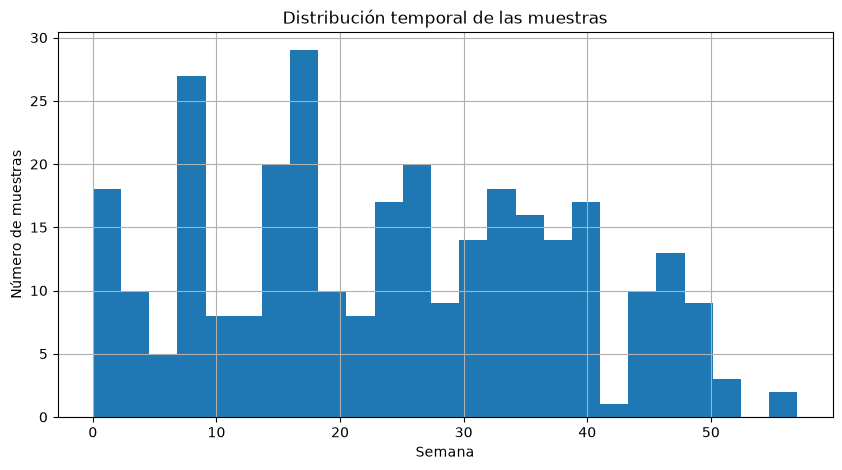

In [84]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

master_core["week_num"].hist(bins=25)

plt.xlabel("Semana")
plt.ylabel("Número de muestras")
plt.title("Distribución temporal de las muestras")

plt.show()

Número de visitas

In [85]:
master_core["visit_num"].describe()

count    306.000000
mean      17.133987
std        7.705545
min        4.000000
25%       11.250000
50%       18.000000
75%       25.000000
max       30.000000
Name: visit_num, dtype: float64

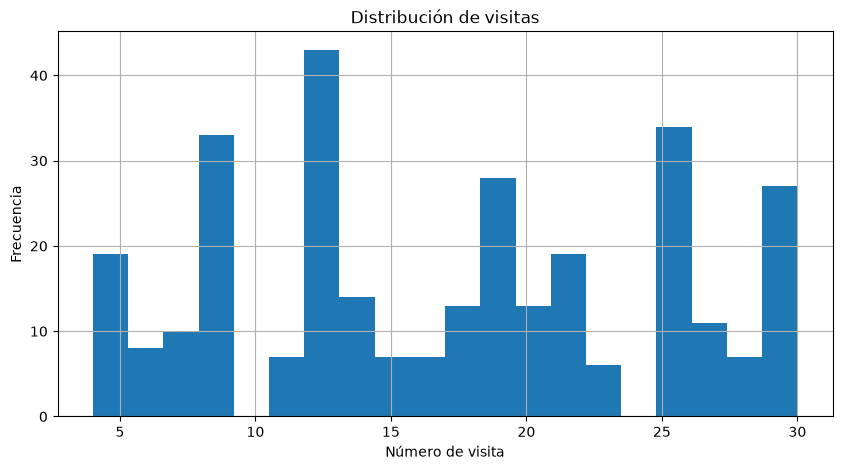

In [86]:
plt.figure(figsize=(10,5))

master_core["visit_num"].hist(bins=20)

plt.xlabel("Número de visita")
plt.ylabel("Frecuencia")
plt.title("Distribución de visitas")

plt.show()

Variables clínicas

Ahora veremos qué tan completas son las variables clínicas dentro del Master Core, ya que anteriormente lo hicimos sobre las 2892 muestras.

In [87]:
clinical = [
    "hbi",
    "sccai",
    "fecalcal",
    "CRP (mg/L)",
    "ESR (mm/hr)",
    "Weight",
    "Height",
    "BMI"
]

clinical_summary = []

for c in clinical:

    clinical_summary.append({

        "Variable": c,

        "No nulos": master_core[c].notna().sum(),

        "Nulos": master_core[c].isna().sum(),

        "% Completitud":
            round(master_core[c].notna().mean()*100,2)

    })

clinical_summary = pd.DataFrame(clinical_summary)

display(clinical_summary)

,Variable,No nulos,Nulos,% Completitud
0,hbi,130,176,42.48
1,sccai,78,228,25.49
2,fecalcal,177,129,57.84
3,CRP (mg/L),0,306,0.00
4,ESR (mm/hr),0,306,0.00
5,Weight,0,306,0.00
6,Height,0,306,0.00
7,BMI,0,306,0.00


Interpretación del EDA del Master Core

El conjunto de datos principal quedó conformado por 306 muestras fecales, pertenecientes a 100 participantes, para las cuales existe información simultánea de metagenómica, metatranscriptómica y metabolómica. Este subconjunto representa el núcleo del estudio y constituye la población sobre la cual se desarrollarán los análisis posteriores.

La distribución por diagnóstico muestra que aproximadamente la mitad de las muestras corresponden a pacientes con enfermedad de Crohn (46.7%), mientras que la colitis ulcerosa representa un 25.2% y los individuos sin enfermedad inflamatoria intestinal un 28.1%. Aunque existe un predominio moderado de Crohn, el conjunto mantiene representación de los tres grupos clínicos, lo que permitirá evaluar anomalías tanto dentro de cada diagnóstico como entre diagnósticos diferentes.

La distribución por sexo es prácticamente equilibrada, con un 52.6% de hombres y un 47.4% de mujeres, reduciendo el riesgo de que el sexo actúe como un factor de sesgo importante durante el entrenamiento de los modelos.

Respecto al origen de las muestras, la mayor parte procede de cuatro centros clínicos principales: Massachusetts General Hospital (29.7%), Cincinnati Children's Hospital (29.4%), Cedars-Sinai (24.2%) y MGH Pediatrics (14.1%), mientras que Emory aporta un porcentaje reducido (2.6%). Esta distribución indica que el conjunto incorpora variabilidad proveniente de múltiples instituciones, aspecto que posteriormente permitirá evaluar si algunas anomalías pudieran asociarse a efectos de sitio o lote.

El análisis temporal evidencia que las muestras cubren prácticamente todo el período de seguimiento del estudio, desde la semana 0 hasta la semana 57. La mediana cercana a las 25 semanas indica que la mayoría de los individuos fueron observados durante varios meses, proporcionando suficiente información longitudinal para estudiar cambios intraindividuales además de diferencias entre sujetos.

De forma similar, las visitas clínicas abarcan desde la visita 4 hasta la visita 30, con una mediana de 18 visitas, reflejando que la mayor parte de las muestras procede de pacientes con seguimiento relativamente prolongado.

En cuanto a la disponibilidad de información clínica, únicamente algunas variables presentan un nivel de completitud suficiente para incorporarlas posteriormente como apoyo en la interpretación biológica de las anomalías detectadas. La concentración fecal de calprotectina constituye la variable más completa (57.8%), seguida por el índice HBI (42.5%) y el índice SCCAI (25.5%). En contraste, variables como proteína C reactiva (CRP), velocidad de sedimentación globular (ESR), peso, talla e índice de masa corporal no presentan información disponible dentro del subconjunto principal, por lo que no podrán emplearse como variables auxiliares durante la validación clínica de los resultados.

In [88]:
master_core[
    [
        "CRP (mg/L)",
        "ESR (mm/hr)",
        "Weight",
        "Height",
        "BMI"
    ]
].head(10)

,CRP (mg/L),ESR (mm/hr),Weight,Height,BMI
532,<NA>,<NA>,<NA>,<NA>,<NA>
544,<NA>,<NA>,<NA>,<NA>,<NA>
553,<NA>,<NA>,<NA>,<NA>,<NA>
561,<NA>,<NA>,<NA>,<NA>,<NA>
572,<NA>,<NA>,<NA>,<NA>,<NA>
583,<NA>,<NA>,<NA>,<NA>,<NA>
588,<NA>,<NA>,<NA>,<NA>,<NA>
606,<NA>,<NA>,<NA>,<NA>,<NA>
607,<NA>,<NA>,<NA>,<NA>,<NA>
627,<NA>,<NA>,<NA>,<NA>,<NA>


In [89]:
master_core[
    [
        "CRP (mg/L)",
        "ESR (mm/hr)",
        "Weight",
        "Height",
        "BMI"
    ]
].dtypes

CRP (mg/L)     object
ESR (mm/hr)    object
Weight         object
Height         object
BMI            object
dtype: object

In [90]:
core_ids = set(master_core["External ID"])

df_core_original = df_csv[
    df_csv["External ID"].isin(core_ids)
]

print(df_core_original.shape)

(1367, 490)


In [91]:
variables = [
    "CRP (mg/L)",
    "ESR (mm/hr)",
    "Weight",
    "Height",
    "BMI"
]

for v in variables:
    print("="*60)
    print(v)
    print(df_core_original[v].notna().sum())

CRP (mg/L)
0
ESR (mm/hr)
0
Weight
0
Height
0
BMI
0


FASE 3 – Preparación de la matriz MGX

Nuestro objetivo es construir una matriz que tenga la siguiente estructura:

| Taxón            | Muestra 1 | Muestra 2 | ... |
| ---------------- | --------: | --------: | --: |
| Bacteroides      |       ... |       ... | ... |
| Faecalibacterium |       ... |       ... | ... |
| Prevotella       |       ... |       ... | ... |


Paso 3.1 – Extraer únicamente las muestras del Master Core

Hasta ahora, la matriz MGX contiene 1638 muestras, pero nosotros solo trabajaremos con las 306 del dataset integrado.

In [92]:
# IDs del dataset principal
core_ids = master_core["External ID"].tolist()

# Primera columna = taxones
tax_column = mgx_tax.columns[0]

# Columnas presentes en MGX
selected_cols = [
    tax_column
] + [
    c for c in core_ids
    if c in mgx_tax.columns
]

mgx_core = mgx_tax[selected_cols].copy()

print(mgx_core.shape)

display(mgx_core.iloc[:5, :5])

(1479, 307)


,#SampleID,CSM5MCVN,CSM5MCWE,CSM5MCX3,CSM5MCXL
0,k__Archaea,0.0,0.0,0.0,0.0
1,k__Archaea|p__Euryarchaeota,0.0,0.0,0.0,0.0
2,k__Archaea|p__Euryarchaeota|c__Methanobacteria,0.0,0.0,0.0,0.0
3,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0
4,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0


Paso 3.2 – Verificar la correspondencia

Después comprobaremos que no se haya perdido ninguna muestra.

In [93]:
mgx_samples = set(mgx_core.columns[1:])
master_samples = set(master_core["External ID"])

print("Muestras Master:", len(master_samples))
print("Muestras MGX:", len(mgx_samples))

print()

print("Intersección:",
      len(master_samples & mgx_samples))

print("Faltantes:",
      len(master_samples - mgx_samples))

Muestras Master: 306
Muestras MGX: 306

Intersección: 306
Faltantes: 0


Paso 3.3 – Caracterizar la matriz MGX

Antes de decidir cualquier filtrado necesitamos conocer sus propiedades.

In [94]:
print("Número de taxones:", mgx_core.shape[0])
print("Número de muestras:", mgx_core.shape[1]-1)

print()

# Porcentaje de ceros
X = mgx_core.iloc[:,1:]

zeros = (X == 0).sum().sum()

total = X.size

print("Porcentaje de ceros:",
      round(100*zeros/total,2),"%")

print()

print("Valor mínimo:",
      X.min().min())

print("Valor máximo:",
      X.max().max())

print()

print("Media global:",
      X.values.mean())

Número de taxones: 1479
Número de muestras: 306

Porcentaje de ceros: 87.75 %

Valor mínimo: 0.0
Valor máximo: 1.0

Media global: 0.005347564346825049


Interpretación de la matriz MGX

La extracción de las muestras fue completamente exitosa. La submatriz contiene 1479 taxones y 306 muestras, coincidiendo exactamente con el número de muestras presentes en el master_core. La validación confirmó una intersección completa entre los identificadores de ambas fuentes, sin pérdidas ni inconsistencias durante el proceso de integración. Esto garantiza que la información taxonómica corresponde exactamente al conjunto de muestras seleccionado para el estudio.

El análisis descriptivo de la matriz revela una característica típica de los datos de microbioma: una elevada dispersión o sparsity. Aproximadamente el 87.75% de los valores son cero, lo que indica que la mayoría de los microorganismos no se encuentran presentes en todas las muestras. Este comportamiento es esperado en estudios metagenómicos y refleja la gran variabilidad biológica existente entre individuos.

Asimismo, los valores de abundancia relativa se encuentran correctamente normalizados dentro del intervalo [0,1], donde 0 representa ausencia del taxón y 1 corresponde a la abundancia relativa máxima posible. La media global de las abundancias es muy baja (0.00535), confirmando que la mayor parte de los taxones aparecen con abundancias reducidas y únicamente un pequeño subconjunto presenta valores elevados.

En conjunto, estos resultados muestran que la matriz posee las características habituales de datos composicionales de microbioma: alta dimensionalidad, abundancia de ceros y distribución fuertemente asimétrica. Estas propiedades deberán considerarse durante el preprocesamiento previo a la detección de anomalías.

Paso 3.4 – Medir la prevalencia de los taxones

Antes de eliminar nada, quiero que observemos la distribución. No tomaremos decisiones "a ciegas".

In [95]:
# Matriz numérica
X = mgx_core.iloc[:, 1:]

# Número de muestras donde aparece cada taxón
prevalence = (X > 0).sum(axis=1)

print(prevalence.describe())

display(prevalence.sort_values())

count    1479.000000
mean       37.483435
std        70.405405
min         0.000000
25%         0.500000
50%         3.000000
75%        27.000000
max       306.000000
dtype: float64


46        0
31        0
1471      0
1478      0
1477      0
       ... 
998     302
602     304
601     304
404     305
9       306
Length: 1479, dtype: int64

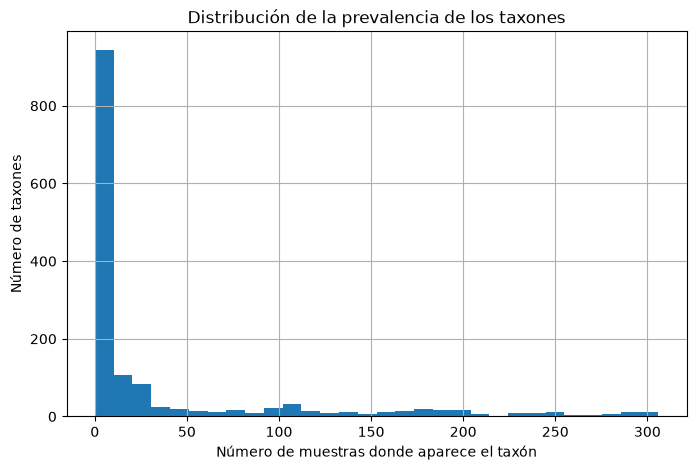

In [96]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

prevalence.hist(bins=30)

plt.xlabel("Número de muestras donde aparece el taxón")
plt.ylabel("Número de taxones")
plt.title("Distribución de la prevalencia de los taxones")

plt.show()

Fase 3.4 – Caracterización de la matriz MGX
Paso 3.4.1 – Distribución de las abundancias distintas de cero
Hasta ahora sabemos que:

* la matriz tiene 1479 taxones;
* contiene 306 muestras;
* el 87.75 % de los valores son cero.
Sin embargo, aún no sabemos cómo se distribuyen las abundancias cuando un taxón está presente. Es decir, queremos responder preguntas como:
* ¿La mayoría de las abundancias son extremadamente pequeñas?
* ¿Existen taxones con abundancias muy elevadas?
* ¿La distribución está sesgada hacia la derecha?

Esta información será importante porque determinará si posteriormente conviene aplicar transformaciones como log1p, CLR o alguna otra transformación composicional.

In [97]:
# Matriz numérica
X = mgx_core.iloc[:, 1:]

# Tomar únicamente abundancias distintas de cero
non_zero = X.values[X.values > 0]

print("Número de valores distintos de cero:", len(non_zero))

print("\nResumen estadístico:")
print(pd.Series(non_zero).describe())

print("\nPercentiles:")
print(
    pd.Series(non_zero).quantile(
        [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Número de valores distintos de cero: 55438

Resumen estadístico:
count    5.543800e+04
mean     4.365541e-02
std      1.371840e-01
min      3.000000e-07
25%      3.077250e-04
50%      1.950000e-03
75%      1.491410e-02
max      1.000000e+00
dtype: float64

Percentiles:
0.25    0.000308
0.50    0.001950
0.75    0.014914
0.90    0.087969
0.95    0.249626
0.99    0.816173
dtype: float64


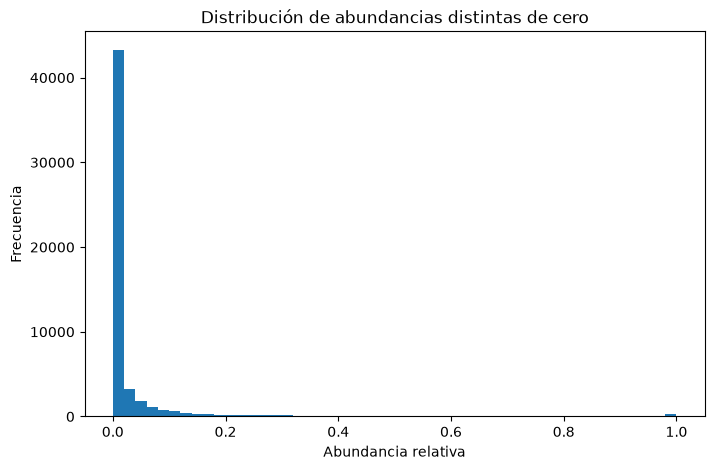

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(non_zero, bins=50)

plt.xlabel("Abundancia relativa")
plt.ylabel("Frecuencia")
plt.title("Distribución de abundancias distintas de cero")

plt.show()

Interpretación de los resultados

La matriz contiene:

* 55.438 valores > 0.
* Abundancia mínima: 3 × 10⁻⁷.
* Primer cuartil: 0.000308.
* Mediana: 0.00195.
* Tercer cuartil: 0.01491.
* Percentil 90: 0.08797.
* Percentil 95: 0.24963.
* Percentil 99: 0.81617.

Esto confirma que la distribución está fuertemente sesgada hacia abundancias extremadamente pequeñas. Hay una gran cantidad de valores positivos muy próximos a cero.

Pero hay un punto metodológico importante:

No vamos a eliminar valores individuales de la matriz.

Eso podría alterar artificialmente la composición de las muestras y, además, podría destruir precisamente una señal que posteriormente queramos detectar como anomalía.

Lo que podemos evaluar es si existen taxones cuya abundancia sea consistentemente tan pequeña que probablemente aporten principalmente ruido numérico.

Siguiente paso: evaluar varios umbrales

En lugar de decidir arbitrariamente "eliminemos todo < 0.001", vamos a estudiar qué ocurre con distintos umbrales.

In [99]:
# Matriz numérica
X = mgx_core.iloc[:, 1:].astype(float)

# Prevalencia original
prevalence_original = (X > 0).sum(axis=1)

thresholds = [
    1e-7,
    1e-6,
    1e-5,
    1e-4,
    5e-4,
    1e-3,
    5e-3,
    1e-2
]

results = []

for threshold in thresholds:

    # Un taxón se considera presente si su abundancia
    # supera el umbral
    presence = X >= threshold

    taxa_retained = presence.any(axis=1).sum()

    taxa_lost = (~presence.any(axis=1)).sum()

    values_retained = (X >= threshold).sum().sum()

    results.append({
        "Umbral": threshold,
        "Taxones retenidos": taxa_retained,
        "Taxones eliminados": taxa_lost,
        "Valores >= umbral": values_retained
    })

threshold_analysis = pd.DataFrame(results)

display(threshold_analysis)

,Umbral,Taxones retenidos,Taxones eliminados,Valores >= umbral
0,1.000000e-07,1109,370,55438
1,1.000000e-06,1109,370,55431
2,1.000000e-05,1101,378,54654
3,1.000000e-04,1011,468,48340
4,5.000000e-04,850,629,37933
5,1.000000e-03,769,710,32816
6,5.000000e-03,634,845,21194
7,1.000000e-02,556,923,16374


In [100]:
# Evaluar qué ocurre con la prevalencia de los taxones
threshold = 1e-4

presence = X >= threshold

prevalence_threshold = presence.sum(axis=1)

comparison = pd.DataFrame({
    "Prevalencia original": prevalence_original,
    "Prevalencia con umbral": prevalence_threshold
})

comparison["Diferencia"] = (
    comparison["Prevalencia original"]
    - comparison["Prevalencia con umbral"]
)

display(comparison.describe())

,Prevalencia original,Prevalencia con umbral,Diferencia
count,1479.000000,1479.000000,1479.000000
mean,37.483435,32.684246,4.799189
std,70.405405,65.127914,8.965856
min,0.000000,0.000000,0.000000
25%,0.500000,0.000000,0.000000
50%,3.000000,2.000000,1.000000
75%,27.000000,22.000000,5.000000
max,306.000000,306.000000,51.000000


Qué nos está mostrando realmente el análisis

Partimos de:

* 306 muestras
* 1479 taxones
* 55.438 valores > 0

Pero hay 370 taxones que nunca aparecen en ninguna muestra. Por eso, incluso con un umbral de 1e-7, solamente quedan 1109 taxones.

Esto significa que esos 370 taxones no representan "microorganismos raros"; son taxones completamente ausentes de nuestro conjunto de 306 muestras.

Esos sí podemos eliminarlos de la matriz analítica sin afectar nuestra capacidad de detectar anomalías.

2. Comparación de los umbrales

| Umbral | Taxones retenidos | Taxones eliminados | Valores retenidos |
| -----: | ----------------: | -----------------: | ----------------: |
|   1e-7 |              1109 |                370 |            55.438 |
|   1e-6 |              1109 |                370 |            55.431 |
|   1e-5 |              1101 |                378 |            54.654 |
|   1e-4 |              1011 |                468 |            48.340 |
|   5e-4 |               850 |                629 |            37.933 |
|   1e-3 |               769 |                710 |            32.816 |
|   5e-3 |               634 |                845 |            21.194 |
|   1e-2 |               556 |                923 |            16.374 |


Aquí se ve algo muy importante.

1e-5 es extremadamente conservador

Con 1e-5:

eliminamos solamente 378 de 1479 taxones;
pero 370 de esos 378 son taxones completamente ausentes;
por lo tanto, solamente 8 taxones realmente observados quedarían fuera.

Es decir:

1479 → 1101 taxones

pero prácticamente toda la reducción corresponde a taxones que no aparecen realmente en nuestras muestras.

3. ¿Y qué pasa con 1e-4?

Aquí cambia bastante la situación.

Con 1e-4:

1479 → 1011 taxones

Se eliminan 468 taxones.

Como 370 son completamente ausentes:

468 − 370 = 98

Eso significa que 98 taxones que sí fueron observados en alguna muestra serían eliminados.

MASTER DATASET
2892 muestras
        │

MASTER CORE
306 muestras
        │
        
MGX CORE
306 × 1479
        │

        ├── 370 taxones completamente ausentes
        │

        └── 1109 taxones observados
                │
                

        Evaluación de abundancia
                │
                
        candidato: umbral 1e-5

In [101]:
threshold = 1e-5

# Máxima abundancia observada por taxón
max_abundance = X.max(axis=1)

# Prevalencia original
prevalence = (X > 0).sum(axis=1)

low_abundance_taxa = pd.DataFrame({
    "max_abundance": max_abundance,
    "prevalence": prevalence
})

# Taxones que tienen alguna presencia,
# pero ninguna abundancia >= 1e-5
low_abundance_taxa = low_abundance_taxa[
    (low_abundance_taxa["prevalence"] > 0) &
    (low_abundance_taxa["max_abundance"] < threshold)
]

print("Taxones observados eliminados por 1e-5:",
      len(low_abundance_taxa))

display(
    low_abundance_taxa.sort_values(
        "max_abundance"
    )
)

Taxones observados eliminados por 1e-5: 8


,max_abundance,prevalence
42,0.000005,1
43,0.000005,1
641,0.000008,1
642,0.000008,1
558,0.000009,1
557,0.000009,1
586,0.000009,1
585,0.000009,1


In [102]:
# Taxones completamente ausentes
zero_taxa = pd.DataFrame({
    "max_abundance": X.max(axis=1),
    "prevalence": (X > 0).sum(axis=1)
})

zero_taxa = zero_taxa[
    zero_taxa["prevalence"] == 0
]

print("Taxones completamente ausentes:",
      len(zero_taxa))

Taxones completamente ausentes: 370


Lo que acabamos de comprobar

De los 1479 taxones originales:

* 370 tienen prevalencia 0 → no aparecen en ninguna de las 306 muestras.
* 8 aparecen realmente, pero su abundancia máxima está entre 5e-6 y 9e-6, es decir, nunca alcanzan 1e-5.
* Los restantes 1101 taxones tienen al menos una observación ≥ 1e-5.

1479 taxones originales
        │

        ├── 370 completamente ausentes
        │

        ├── 8 observados pero con abundancia < 1e-5
        │
        
        └── 1101 taxones conservados

Y los 8 taxones que perderíamos son extremadamente débiles:

| Máxima abundancia | Prevalencia |
| ----------------: | ----------: |
|          0.000005 |           1 |
|          0.000005 |           1 |
|          0.000008 |           1 |
|          0.000008 |           1 |
|          0.000009 |           1 |
|          0.000009 |           1 |
|          0.000009 |           1 |
|          0.000009 |           1 |


In [103]:
# ============================================================
# FILTRADO CONSERVADOR CORRECTO DE MGX
# Umbral de abundancia relativa: 1e-5
# ============================================================

threshold = 1e-5

# Matriz numérica:
# filas = taxones
# columnas = muestras
X = mgx_core.iloc[:, 1:].astype(float)

# Mantener un taxón si alcanza >= 1e-5
# en al menos una muestra
taxa_to_keep = (X >= threshold).any(axis=1)

print("Taxones originales:", X.shape[0])
print("Taxones conservados:", taxa_to_keep.sum())
print("Taxones eliminados:", (~taxa_to_keep).sum())

# Construir matriz filtrada
mgx_filtered = mgx_core.loc[taxa_to_keep].copy()

print("\nDimensiones de mgx_filtered:")
print(mgx_filtered.shape)

display(mgx_filtered.head())

Taxones originales: 1479
Taxones conservados: 1101
Taxones eliminados: 378

Dimensiones de mgx_filtered:
(1101, 307)


,#SampleID,CSM5MCVN,CSM5MCWE,CSM5MCX3,CSM5MCXL,CSM5MCY8,CSM5MCZ3,CSM5MCZF,CSM67UA2,CSM67UAA,...,PSMA265X,PSMA266I,PSMA266Q,PSMA2675,PSMA267J,PSMA267P,PSMA269W,PSMA26A3,PSMB4MBK,PSMB4MC5
0,k__Archaea,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,k__Archaea|p__Euryarchaeota,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,k__Archaea|p__Euryarchaeota|c__Methanobacteria,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [104]:
# ============================================================
# VALIDACIÓN POST-FILTRADO
# ============================================================

X_filtered = mgx_filtered.iloc[:, 1:].astype(float)

print("Número de taxones:", X_filtered.shape[0])
print("Número de muestras:", X_filtered.shape[1])

print("\nTaxones con todos los valores en cero:")
print(
    (X_filtered.sum(axis=1) == 0).sum()
)

print("\nMuestras con todos los valores en cero:")
print(
    (X_filtered.sum(axis=0) == 0).sum()
)

print("\nValores mínimos y máximos:")
print("Mínimo:", X_filtered.min().min())
print("Máximo:", X_filtered.max().max())

print("\nPorcentaje de ceros:")
print(
    round(
        (X_filtered == 0).sum().sum()
        / X_filtered.size * 100,
        2
    ),
    "%"
)

Número de taxones: 1101
Número de muestras: 306

Taxones con todos los valores en cero:
0

Muestras con todos los valores en cero:
0

Valores mínimos y máximos:
Mínimo: 0.0
Máximo: 1.0

Porcentaje de ceros:
83.55 %


Resultado actual de MGX

Partimos de:

* 1479 taxones
* 306 muestras

Aplicando el umbral conservador de abundancia relativa:

abundancia≥10e−5

| Métrica                        |  Antes |    Después |
| ------------------------------ | -----: | ---------: |
| Taxones                        |   1479 |   **1101** |
| Muestras                       |    306 |    **306** |
| Taxones eliminados             |      — |    **378** |
| Taxones completamente ausentes |    370 |      **0** |
| Muestras completamente en cero |     0* |      **0** |
| Valores cero                   | 87.75% | **83.55%** |
| Mínimo                         |      0 |          0 |
| Máximo                         |      1 |          1 |


In [105]:
# ============================================================
# VALIDACIÓN CORRECTA DE MGX FILTRADO
# ============================================================

X_filtered = mgx_filtered.iloc[:, 1:].astype(float)

print("Número de taxones:", X_filtered.shape[0])
print("Número de muestras:", X_filtered.shape[1])

print("\nTaxones con todos los valores en cero:")
print((X_filtered.sum(axis=1) == 0).sum())

print("\nMuestras con todos los valores en cero:")
print((X_filtered.sum(axis=0) == 0).sum())

print("\nValores mínimos y máximos:")
print("Mínimo:", X_filtered.min().min())
print("Máximo:", X_filtered.max().max())

print("\nPorcentaje de ceros:")
print(
    round(
        (X_filtered == 0).sum().sum()
        / X_filtered.size * 100,
        2
    ),
    "%"
)

Número de taxones: 1101
Número de muestras: 306

Taxones con todos los valores en cero:
0

Muestras con todos los valores en cero:
0

Valores mínimos y máximos:
Mínimo: 0.0
Máximo: 1.0

Porcentaje de ceros:
83.55 %


| Métrica                        |  Resultado |
| ------------------------------ | ---------: |
| Taxones iniciales              |       1479 |
| Taxones conservados            |   **1101** |
| Taxones eliminados             |    **378** |
| Muestras                       |    **306** |
| Taxones completamente en cero  |      **0** |
| Muestras completamente en cero |      **0** |
| Abundancia mínima              |          0 |
| Abundancia máxima              |          1 |
| Porcentaje de ceros            | **83.55%** |


Esto confirma que el filtrado con:

$$ \text{abundancia relativa} \geq 10^{-5} $$

funcionó como esperábamos.

Los 1101 taxones restantes tienen al menos una observación ≥ \(10^{-5}\) y ninguna de las 306 muestras quedó sin información después del filtrado.

Además, la reducción de sparsity de 87.75% → 83.55% indica que eliminamos principalmente taxones extremadamente raros o de abundancia ínfima, pero no estamos eliminando la estructura general de la matriz.

Y esto es especialmente importante para nuestro objetivo: detección de anomalías. No hemos aplicado un filtro agresivo de prevalencia que pudiera eliminar microorganismos poco frecuentes potencialmente relevantes para una anomalía.

Paso 3.5 — Comprobar la composición de las muestras

In [106]:
# ============================================================
# PASO 3.5 — VALIDACIÓN DE COMPOSICIONALIDAD DE MGX
# ============================================================

X_filtered = mgx_filtered.iloc[:, 1:].astype(float)

sample_sums = X_filtered.sum(axis=0)

print("Resumen de la suma de abundancias por muestra:")
print(sample_sums.describe())

print("\nMínimo:", sample_sums.min())
print("Máximo:", sample_sums.max())

print("\nMuestras con suma ≈ 1:")
print(
    ((sample_sums - 1).abs() < 1e-6).sum(),
    "de",
    len(sample_sums)
)

print("\nMuestras con suma ≠ 1:")
print(
    ((sample_sums - 1).abs() >= 1e-6).sum()
)

Resumen de la suma de abundancias por muestra:
count    306.000000
mean       7.909047
std        0.147735
min        6.000000
25%        7.894384
50%        7.948677
75%        7.970762
max        8.000002
dtype: float64

Mínimo: 6.0
Máximo: 8.0000021

Muestras con suma ≈ 1:
0 de 306

Muestras con suma ≠ 1:
306


Obtuvimos:

Media:   7.909
Mínimo:  6.000
Máximo:  8.000002

y:

Muestras con suma ≈ 1: 0 / 306
Muestras con suma ≠ 1: 306 / 306

Por lo tanto, la matriz no está normalizada por muestra para que sus abundancias sumen 1.

Hay una pista muy importante

Las sumas están concentradas alrededor de 8:

mínimo ≈ 6
mediana ≈ 7.95
máximo ≈ 8

Eso sugiere que los valores de mgx_core probablemente corresponden a una transformación o escala específica del perfil taxonómico, y no a abundancias relativas convencionales.

In [107]:
# ============================================================
# PASO 3.6 — DISTRIBUCIÓN DE LA SUMA TOTAL POR MUESTRA
# ============================================================

sample_sums = X_filtered.sum(axis=0)

print("Suma total por muestra:")
display(sample_sums.sort_values().to_frame("sample_sum").head(10))

print("\nMuestras con suma más alta:")
display(sample_sums.sort_values(ascending=False)
        .to_frame("sample_sum")
        .head(10))

print("\nValores únicos aproximados de las sumas:")
display(
    pd.Series(
        sample_sums.round(4)
    ).value_counts().sort_index().head(30)
)

Suma total por muestra:


,sample_sum
CSM7KOOR,6.000000
HSM5MD7O,7.166747
HSM7J4QJ,7.325681
HSM7CYX2,7.439579
CSM79HPA,7.508015
CSM79HH8,7.534923
PSM7J177,7.573388
HSM7J4OT,7.641177
MSM6J2PU,7.678282
CSM7KOTK,7.678579



Muestras con suma más alta:


,sample_sum
HSM7J4LP,8.000002
PSM7J161,7.997143
MSM5LLDS,7.997033
MSM6J2OP,7.996600
HSM67VH1,7.995334
HSM6XRRJ,7.994884
CSM7KOSP,7.994707
MSMA26AZ,7.994685
CSM79HIB,7.994261
MSM79HDE,7.993952



Valores únicos aproximados de las sumas:


6.0000    1
7.1667    1
7.3257    1
7.4396    1
7.5080    1
7.5349    1
7.5734    1
7.6412    1
7.6783    1
7.6786    1
7.6802    1
7.6875    1
7.6924    1
7.6998    1
7.7072    1
7.7284    1
7.7379    1
7.7410    1
7.7452    1
7.7557    1
7.7635    1
7.7809    1
7.7874    1
7.7877    1
7.7928    1
7.7966    1
7.8079    1
7.8110    1
7.8137    1
7.8141    1
Name: count, dtype: int64

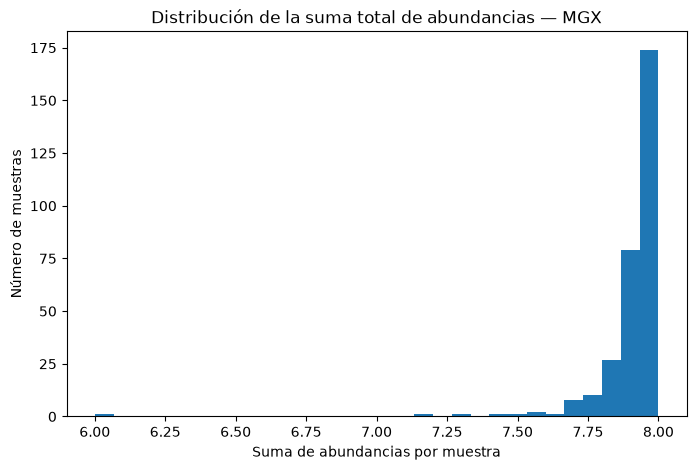

In [108]:
# ============================================================
# Distribución gráfica
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(sample_sums, bins=30)

plt.xlabel("Suma de abundancias por muestra")
plt.ylabel("Número de muestras")
plt.title("Distribución de la suma total de abundancias — MGX")

plt.show()

La suma de abundancias por muestra debería ser aproximadamente 1 si estuviéramos trabajando con una matriz de abundancias relativas donde cada fila representa categorías taxonómicas mutuamente excluyentes.

Pero tenemos:

* mínimo: 6.0
* máximo: 8.000002
* media: 7.909
* muestras con suma ≈ 1: 0/306

Esto no significa que los datos estén mal.

Lo más probable es que taxonomic_profiles.tsv.gz contenga múltiples niveles taxonómicos simultáneamente.

k__Bacteria
k__Bacteria|p__Firmicutes
k__Bacteria|p__Firmicutes|c__Clostridia
k__Bacteria|p__Firmicutes|c__Clostridia|o__...
...

Es decir, no podemos sumar:

Kingdom
+ Phylum
+ Class
+ Order
+ Family
+ Genus
+ Species

In [109]:
# ============================================================
# IDENTIFICACIÓN DE NIVELES TAXONÓMICOS
# ============================================================

taxa = mgx_filtered.iloc[:, 0].astype(str)

def taxonomic_level(taxon):

    if "|s__" in taxon:
        return "species"
    elif "|g__" in taxon:
        return "genus"
    elif "|f__" in taxon:
        return "family"
    elif "|o__" in taxon:
        return "order"
    elif "|c__" in taxon:
        return "class"
    elif "|p__" in taxon:
        return "phylum"
    elif "k__" in taxon:
        return "kingdom"
    else:
        return "unknown"


taxonomic_levels = taxa.apply(taxonomic_level)

taxonomy_info = pd.DataFrame({
    "taxon": taxa,
    "level": taxonomic_levels
})

print("Distribución de niveles taxonómicos:")
display(taxonomic_levels.value_counts())

Distribución de niveles taxonómicos:


#SampleID
species    812
genus      149
family      67
order       32
class       23
phylum      14
kingdom      4
Name: count, dtype: int64

In [110]:
taxonomy_info = pd.DataFrame({
    "taxon": taxa,
    "level": taxonomic_levels
})

print("Ejemplos por nivel:")
display(
    taxonomy_info.groupby("level").head(5)
)

Ejemplos por nivel:


,taxon,level
0,k__Archaea,kingdom
1,k__Archaea|p__Euryarchaeota,phylum
2,k__Archaea|p__Euryarchaeota|c__Methanobacteria,class
3,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,order
4,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,family
5,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,genus
6,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,species
7,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,species
8,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,species
9,k__Bacteria,kingdom


3.5 — Interpretación de la estructura taxonómica

Después del filtrado conservador con 1e-5, quedaron 1101 taxones distribuidos de la siguiente manera:

| Nivel taxonómico | Nº de taxones |
| ---------------- | ------------: |
| Species          |           812 |
| Genus            |           149 |
| Family           |            67 |
| Order            |            32 |
| Class            |            23 |
| Phylum           |            14 |
| Kingdom          |             4 |
| **Total**        |      **1101** |


Esto confirma algo importante: la matriz actual contiene simultáneamente varios niveles de la jerarquía taxonómica.

Por ejemplo, una misma muestra puede contener:

k__Bacteria
k__Bacteria|p__Bacteroidetes
k__Bacteria|p__Bacteroidetes|c__Bacteroidia
k__Bacteria|p__Bacteroidetes|c__Bacteroidia|...
...
k__Bacteria|p__Bacteroidetes|...|species

Por lo tanto, esos 1101 taxones no representan 1101 microorganismos independientes. Muchos corresponden a diferentes niveles de la misma jerarquía.

Esto explica el resultado anterior de las sumas

Recordemos que obtuvimos:

Media de suma por muestra ≈ 7.91
Mínimo = 6.0
Máximo ≈ 8.0

y ninguna muestra tenía suma ≈ 1.

Esto no significa que los datos estén necesariamente mal normalizados.

La razón es que estamos sumando simultáneamente:

kingdom
+
phylum
+
class
+
order
+
family
+
genus
+
species

Las abundancias de los niveles superiores contienen información agregada de los niveles inferiores. Por eso no podemos interpretar la suma de los 1101 features como una composición cuya suma debería ser 1.

In [111]:
display(taxonomy_info["level"].value_counts())

level
species    812
genus      149
family      67
order       32
class       23
phylum      14
kingdom      4
Name: count, dtype: int64

In [112]:
# ============================================================
# MATRIZ MGX — SPECIES
# ============================================================

species_taxa = taxonomy_info.loc[
    taxonomy_info["level"] == "species",
    "taxon"
].tolist()

mgx_species = mgx_filtered[
    mgx_filtered.iloc[:, 0].isin(species_taxa)
].copy()

print("MGX Species")
print("Taxones:", mgx_species.shape[0])
print("Muestras:", mgx_species.shape[1] - 1)

display(mgx_species.head())

MGX Species
Taxones: 812
Muestras: 306


,#SampleID,CSM5MCVN,CSM5MCWE,CSM5MCX3,CSM5MCXL,CSM5MCY8,CSM5MCZ3,CSM5MCZF,CSM67UA2,CSM67UAA,...,PSMA265X,PSMA266I,PSMA266Q,PSMA2675,PSMA267J,PSMA267P,PSMA269W,PSMA26A3,PSMB4MBK,PSMB4MC5
6,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
15,k__Bacteria|p__Acidobacteria|c__Acidobacteriia...,0.0,0.0,0.0,0.0,0.0,0.00012,0.0,0.000122,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
27,k__Bacteria|p__Actinobacteria|c__Actinobacteri...,0.0,0.0,0.0,0.0,0.0,0.00000,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [113]:
# ============================================================
# MATRIZ MGX — GENUS
# ============================================================

genus_taxa = taxonomy_info.loc[
    taxonomy_info["level"] == "genus",
    "taxon"
].tolist()

mgx_genus = mgx_filtered[
    mgx_filtered.iloc[:, 0].isin(genus_taxa)
].copy()

print("MGX Genus")
print("Taxones:", mgx_genus.shape[0])
print("Muestras:", mgx_genus.shape[1] - 1)

MGX Genus
Taxones: 149
Muestras: 306


In [114]:
# ============================================================
# MATRICES MGX POR NIVEL TAXONÓMICO
# ============================================================

taxonomic_levels = [
    "family",
    "order",
    "class",
    "phylum",
    "kingdom"
]

mgx_by_level = {}

for level in taxonomic_levels:

    taxa_level = taxonomy_info.loc[
        taxonomy_info["level"] == level,
        "taxon"
    ].tolist()

    matrix = mgx_filtered[
        mgx_filtered.iloc[:, 0].isin(taxa_level)
    ].copy()

    mgx_by_level[level] = matrix

    print(
        f"{level.capitalize():10s} -> "
        f"Taxones: {matrix.shape[0]:3d} | "
        f"Muestras: {matrix.shape[1] - 1:3d}"
    )

Family     -> Taxones:  67 | Muestras: 306
Order      -> Taxones:  32 | Muestras: 306
Class      -> Taxones:  23 | Muestras: 306
Phylum     -> Taxones:  14 | Muestras: 306
Kingdom    -> Taxones:   4 | Muestras: 306


In [115]:
# ============================================================
# VALIDACIÓN DE LAS MATRICES TAXONÓMICAS
# ============================================================

all_matrices = {
    "species": mgx_species,
    "genus": mgx_genus,
    **mgx_by_level
}

for level, matrix in all_matrices.items():

    X_level = matrix.iloc[:, 1:].astype(float)

    print("=" * 60)
    print(level.upper())

    print("Taxones:", X_level.shape[0])
    print("Muestras:", X_level.shape[1])

    print(
        "Taxones completamente en cero:",
        (X_level.sum(axis=1) == 0).sum()
    )

    print(
        "Muestras completamente en cero:",
        (X_level.sum(axis=0) == 0).sum()
    )

    print("Mínimo:", X_level.min().min())
    print("Máximo:", X_level.max().max())

SPECIES
Taxones: 812
Muestras: 306
Taxones completamente en cero: 0
Muestras completamente en cero: 1
Mínimo: 0.0
Máximo: 0.902484
GENUS
Taxones: 149
Muestras: 306
Taxones completamente en cero: 0
Muestras completamente en cero: 0
Mínimo: 0.0
Máximo: 1.0
FAMILY
Taxones: 67
Muestras: 306
Taxones completamente en cero: 0
Muestras completamente en cero: 0
Mínimo: 0.0
Máximo: 1.0
ORDER
Taxones: 32
Muestras: 306
Taxones completamente en cero: 0
Muestras completamente en cero: 0
Mínimo: 0.0
Máximo: 1.0
CLASS
Taxones: 23
Muestras: 306
Taxones completamente en cero: 0
Muestras completamente en cero: 0
Mínimo: 0.0
Máximo: 1.0
PHYLUM
Taxones: 14
Muestras: 306
Taxones completamente en cero: 0
Muestras completamente en cero: 0
Mínimo: 0.0
Máximo: 1.0
KINGDOM
Taxones: 4
Muestras: 306
Taxones completamente en cero: 0
Muestras completamente en cero: 0
Mínimo: 0.0
Máximo: 1.0


                  MGX
                   │
          1101 features
                   │
       ┌───────────┴───────────┐
       │                       │
  Taxonomía                Taxonomía
   completa                 separada
       │                       │
       └───────┬───────────────┘
               │
       ┌───────┴────────┐
       │                │
   Species            Genus
   812                 149
       │                │
       └────────┬───────┘
                │
             Family
               67
                │
              ...

In [116]:
# ============================================================
# IDENTIFICAR MUESTRAS SIN TAXONES A NIVEL SPECIES
# ============================================================

X_species = mgx_species.iloc[:, 1:].astype(float)

species_sample_sums = X_species.sum(axis=0)

zero_species_samples = species_sample_sums[
    species_sample_sums == 0
]

print("Muestras sin abundancia a nivel Species:")
display(zero_species_samples)

Muestras sin abundancia a nivel Species:


CSM7KOOR    0.0
dtype: float64

In [117]:
# ============================================================
# COMPARAR LA MUESTRA ENTRE NIVELES TAXONÓMICOS
# ============================================================

sample_id = zero_species_samples.index[0]

print("SampleID:", sample_id)
print()

for level, matrix in all_matrices.items():

    X_level = matrix.iloc[:, 1:].astype(float)

    if sample_id in X_level.columns:
        total = X_level[sample_id].sum()

        print(
            f"{level.capitalize():10s} -> "
            f"suma de abundancias = {total:.6f}"
        )

SampleID: CSM7KOOR

Species    -> suma de abundancias = 0.000000
Genus      -> suma de abundancias = 1.000000
Family     -> suma de abundancias = 1.000000
Order      -> suma de abundancias = 1.000000
Class      -> suma de abundancias = 1.000000
Phylum     -> suma de abundancias = 1.000000
Kingdom    -> suma de abundancias = 1.000000


In [118]:
# ============================================================
# COMPARACIÓN ANTES / DESPUÉS DEL FILTRADO
# ============================================================

sample_id = zero_species_samples.index[0]

X_original = mgx_core.iloc[:, 1:].astype(float)

X_filtered_all = mgx_filtered.iloc[:, 1:].astype(float)

print("SampleID:", sample_id)
print()

print(
    "Taxones > 0 antes del filtrado:",
    (X_original[sample_id] > 0).sum()
)

print(
    "Taxones >= 1e-5 después del filtrado:",
    (X_filtered_all[sample_id] >= 1e-5).sum()
)

print(
    "Suma antes del filtrado:",
    X_original[sample_id].sum()
)

print(
    "Suma después del filtrado:",
    X_filtered_all[sample_id].sum()
)

SampleID: CSM7KOOR

Taxones > 0 antes del filtrado: 6
Taxones >= 1e-5 después del filtrado: 6
Suma antes del filtrado: 6.0
Suma después del filtrado: 6.0


La muestra no está vacía ni tiene un problema de abundancia metagenómica.

Los resultados muestran:

| Comprobación                        | Resultado |
| ----------------------------------- | --------: |
| Taxones > 0 antes del filtrado      |     **6** |
| Taxones ≥ 1e-5 después del filtrado |     **6** |
| Suma antes del filtrado             |   **6.0** |
| Suma después del filtrado           |   **6.0** |
| Species                             |   **0.0** |
| Genus                               |   **1.0** |
| Family                              |   **1.0** |
| Order                               |   **1.0** |
| Class                               |   **1.0** |
| Phylum                              |   **1.0** |
| Kingdom                             |   **1.0** |


CSM7KOOR tiene información metagenómica, pero no tiene ninguna asignación a nivel Species.

Sin embargo, sí tiene información taxonómica en niveles superiores:

Species   → 0

Genus     → 1

Family    → 1

Order     → 1

Class     → 1

Phylum    → 1

Kingdom   → 1

comprobamos que el problema no fue causado por nuestro filtro 1e-5, porque:

Antes del filtrado       → 6 taxones > 0

Después del filtrado     → 6 taxones ≥ 1e-5

Es decir, el filtro conservó toda la información que existía en esa muestra.

In [119]:
# ============================================================
# COBERTURA DE INFORMACIÓN POR NIVEL TAXONÓMICO
# ============================================================

for level, matrix in all_matrices.items():

    X_level = matrix.iloc[:, 1:].astype(float)

    sample_sums = X_level.sum(axis=0)

    n_zero = (sample_sums == 0).sum()
    n_nonzero = (sample_sums > 0).sum()

    print("=" * 60)
    print(level.upper())

    print("Muestras con información:", n_nonzero)
    print("Muestras sin información:", n_zero)

    print(
        "Cobertura:",
        round(n_nonzero / len(sample_sums) * 100, 2),
        "%"
    )

SPECIES
Muestras con información: 305
Muestras sin información: 1
Cobertura: 99.67 %
GENUS
Muestras con información: 306
Muestras sin información: 0
Cobertura: 100.0 %
FAMILY
Muestras con información: 306
Muestras sin información: 0
Cobertura: 100.0 %
ORDER
Muestras con información: 306
Muestras sin información: 0
Cobertura: 100.0 %
CLASS
Muestras con información: 306
Muestras sin información: 0
Cobertura: 100.0 %
PHYLUM
Muestras con información: 306
Muestras sin información: 0
Cobertura: 100.0 %
KINGDOM
Muestras con información: 306
Muestras sin información: 0
Cobertura: 100.0 %


In [120]:
import pandas as pd
import numpy as np

summary_taxonomic = []

for level, matrix in all_matrices.items():

    # Matriz numérica: filas = taxones, columnas = muestras
    X = matrix.iloc[:, 1:].astype(float)

    # Cobertura
    sample_sums = X.sum(axis=0)

    # Prevalencia de cada taxón
    prevalence = (X > 0).sum(axis=1)

    # Estadísticas de abundancia
    nonzero_values = X.values[X.values > 0]

    summary_taxonomic.append({
        "Nivel": level,
        "Features": X.shape[0],
        "Muestras": X.shape[1],
        "Muestras_con_informacion": (sample_sums > 0).sum(),
        "Cobertura_%": round((sample_sums > 0).mean() * 100, 2),
        "Ceros_%": round((X == 0).mean().mean() * 100, 2),
        "Prevalencia_media": round(prevalence.mean(), 2),
        "Prevalencia_mediana": round(prevalence.median(), 2),
        "Prevalencia_min": prevalence.min(),
        "Prevalencia_max": prevalence.max(),
        "Abundancia_media_no_cero": round(nonzero_values.mean(), 6),
        "Abundancia_mediana_no_cero": round(np.median(nonzero_values), 6),
        "Abundancia_max": round(nonzero_values.max(), 6)
    })

summary_taxonomic = pd.DataFrame(summary_taxonomic)

summary_taxonomic

,Nivel,Features,Muestras,Muestras_con_informacion,Cobertura_%,Ceros_%,Prevalencia_media,Prevalencia_mediana,Prevalencia_min,Prevalencia_max,Abundancia_media_no_cero,Abundancia_mediana_no_cero,Abundancia_max
0,species,812,306,305,99.67,86.63,40.92,8.0,1,294,0.017581,0.001352,0.902484
1,genus,149,306,306,100.00,80.35,60.14,13.0,1,296,0.034148,0.002280,1.000000
2,family,67,306,306,100.00,72.42,84.40,18.0,1,300,0.054111,0.004117,1.000000
3,order,32,306,306,100.00,68.59,96.12,20.5,1,304,0.099480,0.002890,1.000000
4,class,23,306,306,100.00,63.09,112.96,21.0,1,304,0.117783,0.005619,1.000000
5,phylum,14,306,306,100.00,65.69,105.00,18.5,1,305,0.208163,0.029990,1.000000
6,kingdom,4,306,306,100.00,63.89,110.50,63.5,9,306,0.692308,0.999850,1.000000


In [121]:
print(summary_taxonomic.to_string(index=False))

  Nivel  Features  Muestras  Muestras_con_informacion  Cobertura_%  Ceros_%  Prevalencia_media  Prevalencia_mediana  Prevalencia_min  Prevalencia_max  Abundancia_media_no_cero  Abundancia_mediana_no_cero  Abundancia_max
species       812       306                       305        99.67    86.63              40.92                  8.0                1              294                  0.017581                    0.001352        0.902484
  genus       149       306                       306       100.00    80.35              60.14                 13.0                1              296                  0.034148                    0.002280        1.000000
 family        67       306                       306       100.00    72.42              84.40                 18.0                1              300                  0.054111                    0.004117        1.000000
  order        32       306                       306       100.00    68.59              96.12                 20.5     

Hay tres observaciones importantes.

A. Species tiene la mayor resolución

Tenemos:

812 especies

pero también:

86.63 % de ceros

y una prevalencia mediana de solamente:

8 muestras de 306.

Esto significa que muchas especies son bastante raras.

Pero, para nuestro problema, esto no significa automáticamente que debamos eliminarlas.

Precisamente porque estamos haciendo detección de anomalías, una especie que aparece en muy pocas muestras podría ser:

ruido técnico,
contaminación,
error de asignación,

pero también podría representar:

una característica biológica poco frecuente,
una alteración asociada a determinado estado,
una señal específica de un paciente,
una posible anomalía real.

Por eso nuestra decisión anterior de no hacer un filtro agresivo por prevalencia sigue siendo correcta.

149 géneros

con:

100 % de cobertura

y una reducción del porcentaje de ceros:

86.63 % → 80.35 %

Además, la prevalencia mediana aumenta:

8 → 13 muestras.

Esto es importante porque el nivel de género conserva bastante resolución biológica, pero reduce considerablemente la dispersión y la rareza extrema que vemos a nivel de especie.

Por eso, genus es actualmente un candidato muy fuerte para nuestra representación principal de MGX.

Por ejemplo:

Family

67 features y 72.42 % de ceros.

Order

32 features y 68.59 % de ceros.

Class

23 features.

Phylum

14 features.

Kingdom

solamente 4 features.

Aunque estos niveles tienen mayor cobertura/prevalencia, cada vez tenemos menos variables capaces de distinguir muestras.

Esto es especialmente importante para anomalías.

Imagina dos muestras:

Muestra A
Species → muchas diferencias
Genus   → diferencias
Family  → diferencias pequeñas
Phylum  → prácticamente iguales
Kingdom → iguales

Si trabajáramos solamente con Kingdom, perderíamos casi toda esa información.

Por tanto, Kingdom no es apropiado como representación principal para nuestro modelo de anomalías.

comprobemos las sumas por muestra para Species y Genus, que son nuestros dos principales candidatos.

In [122]:
for level in ["species", "genus", "family"]:
    
    X = all_matrices[level].iloc[:, 1:].astype(float)
    
    sample_sums = X.sum(axis=0)
    
    print("=" * 60)
    print(level.upper())
    print("Número de features:", X.shape[0])
    print("Número de muestras:", X.shape[1])
    print("Suma mínima:", sample_sums.min())
    print("Suma máxima:", sample_sums.max())
    print("Suma media:", sample_sums.mean())
    print("Mediana:", sample_sums.median())
    print("Desviación estándar:", sample_sums.std())

SPECIES
Número de features: 812
Número de muestras: 306
Suma mínima: 0.0
Suma máxima: 2.0000006
Suma media: 1.9090474696078428
Mediana: 1.9486783
Desviación estándar: 0.14773496284901005
GENUS
Número de features: 149
Número de muestras: 306
Suma mínima: 0.9999982
Suma máxima: 1.0000017
Suma media: 0.9999999816993463
Mediana: 1.0
Desviación estándar: 4.6686086788817033e-07
FAMILY
Número de features: 67
Número de muestras: 306
Suma mínima: 0.9999986000000001
Suma máxima: 1.0000013
Suma media: 0.9999999640522875
Mediana: 1.0
Desviación estándar: 4.7537586565847044e-07


In [123]:
for level in ["species", "genus", "family"]:
    
    X = all_matrices[level].iloc[:, 1:].astype(float)
    
    sample_sums = X.sum(axis=0)
    
    print("\n", level.upper())
    print(
        "Muestras con suma ≈ 1:",
        np.isclose(sample_sums, 1, atol=1e-5).sum(),
        "de",
        len(sample_sums)
    )


 SPECIES
Muestras con suma ≈ 1: 0 de 306

 GENUS
Muestras con suma ≈ 1: 306 de 306

 FAMILY
Muestras con suma ≈ 1: 306 de 306


| Nivel       | Features | Suma media por muestra |    Mínimo |    Máximo | Interpretación         |
| ----------- | -------: | ---------------------: | --------: | --------: | ---------------------- |
| **Species** |      812 |                 1.9090 |         0 | 2.0000006 | ⚠️ No está cerrado a 1 |
| **Genus**   |      149 |                ~1.0000 | 0.9999982 | 1.0000017 | ✅ Cerrado a 1          |
| **Family**  |       67 |                ~1.0000 | 0.9999986 | 1.0000013 | ✅ Cerrado a 1          |


Y la segunda comprobación lo confirma:

* Species → 0/306 muestras con suma ≈ 1
* Genus   → 306/306
* Family  → 306/306

Esto no es un pequeño error numérico en Species. La desviación es estructural.

¿Qué significa para Species?

Tenemos una muestra con suma:

0

y otras muestras llegan prácticamente a:

2

Mientras que Genus y Family están prácticamente normalizados:

≈ 1

Por tanto, no debemos normalizar Species simplemente asumiendo que ya es una composición cerrada.

Y esto explica algo que vimos anteriormente: la matriz de especies tiene una estructura diferente de las matrices agregadas.

Hay una pista muy importante aquí

Recuerda que CSM7KOOR tenía:

Species → suma = 0
Genus   → suma = 1
Family  → suma = 1

Ahora vemos que esto no es un caso aislado de una muestra cualquiera, sino que Species presenta sistemáticamente una estructura distinta.

Esto nos obliga a investigar por qué antes de aplicar cualquier transformación.

Genus y Family sí están en una situación mucho más limpia

Tenemos:

GENUS

mínimo = 0.9999982
máximo = 1.0000017
media  = 0.99999998
SD     = 4.67 × 10⁻⁷

Esto es prácticamente:

$$ \sum_j x_{ij}=1 $$

para cada muestra.

Lo mismo ocurre con Family.

Por lo tanto, podemos decir que:

Las matrices de Genus y Family presentan una estructura composicional cerrada, mientras que la matriz de Species no presenta esa misma propiedad.

Esta diferencia es metodológicamente relevante.

Entre las dos:

Genus
149 features
80.35 % ceros
mediana de prevalencia = 13
306/306 muestras
Family
67 features
72.42 % ceros
mediana de prevalencia = 18
306/306 muestras

Family es más compacta y menos dispersa, pero perdemos bastante resolución.

Para detección de anomalías, inicialmente me parece más interesante Genus, porque tenemos:

suficiente dimensionalidad para detectar patrones anómalos + 100 % de cobertura + estructura composicional consistente.

Pero vamos a comprobarlo cuantitativamente antes de tomar esa decisión.

investigar Species

Antes de descartar Species, quiero saber qué está causando esa suma de 0–2.

In [124]:
X_species = all_matrices["species"].iloc[:, 1:].astype(float)

sample_sums_species = X_species.sum(axis=0)

species_sum_summary = pd.DataFrame({
    "sample_id": sample_sums_species.index,
    "sum_species": sample_sums_species.values
})

species_sum_summary.sort_values("sum_species").head(15)

,sample_id,sum_species
52,CSM7KOOR,0.000000
90,HSM5MD7O,1.166748
154,HSM7J4QJ,1.325680
116,HSM7CYX2,1.439580
34,CSM79HPA,1.508015
22,CSM79HH8,1.534923
280,PSM7J177,1.573388
151,HSM7J4OT,1.641177
188,MSM6J2PU,1.678280
60,CSM7KOTK,1.678578


In [125]:
species_sum_summary.sort_values(
    "sum_species",
    ascending=False
).head(15)

,sample_id,sum_species
141,HSM7J4LP,2.000001
278,PSM7J161,1.997141
174,MSM5LLDS,1.997031
187,MSM6J2OP,1.996597
100,HSM67VH1,1.995334
106,HSM6XRRJ,1.994883
58,CSM7KOSP,1.994706
242,MSMA26AZ,1.994687
25,CSM79HIB,1.994262
213,MSM79HDE,1.993952


In [126]:
bins = [-0.001, 0.001, 0.5, 0.9, 0.99, 1.01, 1.5, 1.9, 2.01]

pd.cut(
    sample_sums_species,
    bins=bins,
    include_lowest=True
).value_counts().sort_index()

(-0.002, 0.001]      1
(0.001, 0.5]         0
(0.5, 0.9]           0
(0.9, 0.99]          0
(0.99, 1.01]         0
(1.01, 1.5]          3
(1.5, 1.9]          82
(1.9, 2.01]        220
Name: count, dtype: int64

In [127]:
X_genus = all_matrices["genus"].iloc[:, 1:].astype(float)

species_sums = X_species.sum(axis=0)
genus_sums = X_genus.sum(axis=0)

comparison = pd.DataFrame({
    "species_sum": species_sums,
    "genus_sum": genus_sums,
    "difference": species_sums - genus_sums
})

comparison.sort_values(
    "species_sum"
).head(20)

,species_sum,genus_sum,difference
CSM7KOOR,0.000000,1.000000,-1.000000
HSM5MD7O,1.166748,1.000000,0.166749
HSM7J4QJ,1.325680,1.000000,0.325680
HSM7CYX2,1.439580,1.000000,0.439581
CSM79HPA,1.508015,1.000000,0.508015
CSM79HH8,1.534923,1.000000,0.534923
PSM7J177,1.573388,1.000000,0.573388
HSM7J4OT,1.641177,1.000000,0.641177
MSM6J2PU,1.678280,1.000001,0.678279
CSM7KOTK,1.678578,1.000000,0.678577


In [128]:
comparison.describe()

,species_sum,genus_sum,difference
count,306.000000,3.060000e+02,306.000000
mean,1.909047,1.000000e+00,0.909047
std,0.147735,4.668609e-07,0.147735
min,0.000000,9.999982e-01,-1.000000
25%,1.894385,9.999997e-01,0.894385
50%,1.948678,1.000000e+00,0.948679
75%,1.970761,1.000000e+00,0.970760
max,2.000001,1.000002e+00,1.000000


Los resultados muestran:

Species
mínimo       = 0

Q1           = 1.894

mediana      = 1.949

Q3           = 1.971

máximo       = 2.000

Y la distribución es muy clara:
| Rango de suma Species | Nº muestras |
| --------------------- | ----------: |
| ≈ 0                   |           1 |
| 0–0.5                 |           0 |
| 0.5–0.9               |           0 |
| 0.9–0.99              |           0 |
| 0.99–1.01             |           0 |
| 1.01–1.5              |           3 |
| 1.5–1.9               |          82 |
| 1.9–2.01              |     **220** |

Es decir:

220 de las 306 muestras tienen una suma de abundancias de especies entre 1.9 y 2.01.

Eso es demasiado sistemático para considerarlo ruido numérico.

In [129]:
species_taxa = all_matrices["species"].iloc[:, 0].astype(str)

species_info = pd.DataFrame({
    "species": species_taxa
})

species_info["genus"] = species_info["species"].str.extract(
    r"(g__[^|]+)"
)[0]

species_info.head(20)

,species,genus
6,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,g__Methanobrevibacter
7,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,g__Methanobrevibacter
8,k__Archaea|p__Euryarchaeota|c__Methanobacteria...,g__Methanobrevibacter
15,k__Bacteria|p__Acidobacteria|c__Acidobacteriia...,g__Granulicella
27,k__Bacteria|p__Actinobacteria|c__Actinobacteri...,g__Actinomyces
28,k__Bacteria|p__Actinobacteria|c__Actinobacteri...,g__Actinomyces
33,k__Bacteria|p__Actinobacteria|c__Actinobacteri...,g__Actinomyces
34,k__Bacteria|p__Actinobacteria|c__Actinobacteri...,g__Actinomyces
35,k__Bacteria|p__Actinobacteria|c__Actinobacteri...,g__Actinomyces
36,k__Bacteria|p__Actinobacteria|c__Actinobacteri...,g__Actinomyces


In [130]:
species_per_genus = (
    species_info
    .groupby("genus")
    .size()
    .sort_values(ascending=False)
)

species_per_genus.describe()

count    139.000000
mean       5.841727
std        9.049188
min        1.000000
25%        2.000000
50%        3.000000
75%        5.000000
max       73.000000
dtype: float64

In [131]:
species_per_genus.head(20)

genus
g__Bacteroides                   73
g__Clostridium                   42
g__Lactobacillus                 36
g__Streptococcus                 34
g__Prevotella                    33
g__Lachnospiraceae_noname        26
g__Bifidobacterium               22
g__Enterococcus                  21
g__Erysipelotrichaceae_noname    20
g__Eubacterium                   19
g__Siphoviridae_noname           18
g__Alistipes                     17
g__Ruminococcus                  14
g__Blautia                       14
g__Parabacteroides               12
g__Porphyromonas                 10
g__Collinsella                    9
g__Veillonella                    9
g__Fusobacterium                  8
g__Haemophilus                    8
dtype: int64

In [132]:
# Taxonomía
species_taxa = all_matrices["species"].iloc[:, 0].astype(str)
genus_taxa = all_matrices["genus"].iloc[:, 0].astype(str)

species_genus = species_taxa.str.extract(
    r"(g__[^|]+)"
)[0]

# Elegimos una muestra de ejemplo
sample = X_genus.columns[0]

species_sample = X_species[sample].copy()
species_sample.index = species_genus

species_aggregated = species_sample.groupby(level=0).sum()

genus_sample = X_genus[sample].copy()
genus_sample.index = genus_taxa

comparison_example = pd.DataFrame({
    "species_sum_by_genus": species_aggregated,
    "genus_abundance": genus_sample
})

comparison_example["difference"] = (
    comparison_example["species_sum_by_genus"]
    - comparison_example["genus_abundance"]
)

comparison_example.sort_values(
    "difference",
    key=lambda x: x.abs(),
    ascending=False
).head(20)

,species_sum_by_genus,genus_abundance,difference
g__Abiotrophia,0.000000,NaN,NaN
g__Acidaminococcus,0.122568,NaN,NaN
g__Actinobacillus,0.000000,NaN,NaN
g__Actinomyces,0.000000,NaN,NaN
g__Adlercreutzia,0.000000,NaN,NaN
g__Aerococcus,0.000000,NaN,NaN
g__Aggregatibacter,0.000000,NaN,NaN
g__Akkermansia,0.000000,NaN,NaN
g__Alistipes,0.000000,NaN,NaN
g__Alloprevotella,0.000000,NaN,NaN


In [133]:
print("Géneros obtenidos desde Species:",
      species_genus.dropna().nunique())

print("Géneros en matriz Genus:",
      genus_taxa.nunique())

print("\nEjemplos Species:")
print(sorted(species_genus.dropna().unique())[:10])

print("\nEjemplos Genus:")
print(sorted(genus_taxa.unique())[:10])

Géneros obtenidos desde Species: 139
Géneros en matriz Genus: 149

Ejemplos Species:
['g__Abiotrophia', 'g__Acidaminococcus', 'g__Actinobacillus', 'g__Actinomyces', 'g__Adlercreutzia', 'g__Aerococcus', 'g__Aggregatibacter', 'g__Akkermansia', 'g__Alistipes', 'g__Alloprevotella']

Ejemplos Genus:
['k__Archaea|p__Euryarchaeota|c__Methanobacteria|o__Methanobacteriales|f__Methanobacteriaceae|g__Methanobrevibacter', 'k__Bacteria|p__Acidobacteria|c__Acidobacteriia|o__Acidobacteriales|f__Acidobacteriaceae|g__Granulicella', 'k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Actinomyces', 'k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Actinomycetaceae|g__Varibaculum', 'k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Brevibacteriaceae|g__Brevibacterium', 'k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomycetales|f__Micrococcaceae|g__Rothia', 'k__Bacteria|p__Actinobacteria|c__Actinobacteria|o__Actinomyce

In [134]:
common_genera = sorted(
    set(species_genus.dropna()) &
    set(genus_taxa)
)

print("Géneros comunes:", len(common_genera))

Géneros comunes: 0


In [135]:
species_aggregated_common = species_aggregated.reindex(common_genera)

genus_sample_common = genus_sample.reindex(common_genera)

comparison_example = pd.DataFrame({
    "species_sum_by_genus": species_aggregated_common,
    "genus_abundance": genus_sample_common
})

comparison_example["difference"] = (
    comparison_example["species_sum_by_genus"]
    - comparison_example["genus_abundance"]
)

comparison_example["ratio_species_genus"] = (
    comparison_example["species_sum_by_genus"]
    / comparison_example["genus_abundance"].replace(0, np.nan)
)

comparison_example.sort_values(
    "difference",
    key=lambda x: x.abs(),
    ascending=False
).head(20)

,species_sum_by_genus,genus_abundance,difference,ratio_species_genus


In [136]:

# Extraer los nombres taxonómicos originales
species_taxa = all_matrices["species"].iloc[:, 0].astype(str)
genus_taxa = all_matrices["genus"].iloc[:, 0].astype(str)

# Extraer únicamente el identificador del género en ambos niveles
species_genus = species_taxa.str.extract(r"(g__[^|]+)")[0]
genus_names = genus_taxa.str.extract(r"(g__[^|]+)")[0]

print("Géneros extraídos de Species:",
      species_genus.dropna().nunique())

print("Géneros extraídos de Genus:",
      genus_names.dropna().nunique())

common_genera = sorted(
    set(species_genus.dropna()) &
    set(genus_names.dropna())
)

print("Géneros comunes:", len(common_genera))

print("Ejemplos:", common_genera[:10])

Géneros extraídos de Species: 139
Géneros extraídos de Genus: 149
Géneros comunes: 139
Ejemplos: ['g__Abiotrophia', 'g__Acidaminococcus', 'g__Actinobacillus', 'g__Actinomyces', 'g__Adlercreutzia', 'g__Aerococcus', 'g__Aggregatibacter', 'g__Akkermansia', 'g__Alistipes', 'g__Alloprevotella']


In [137]:

import pandas as pd
import numpy as np

X_species = all_matrices["species"].iloc[:, 1:].astype(float)
X_genus = all_matrices["genus"].iloc[:, 1:].astype(float)

# Extraer identificadores de género
species_genus = (
    all_matrices["species"].iloc[:, 0]
    .astype(str)
    .str.extract(r"(g__[^|]+)")[0]
)

genus_names = (
    all_matrices["genus"].iloc[:, 0]
    .astype(str)
    .str.extract(r"(g__[^|]+)")[0]
)

# Seleccionar una muestra distinta de la primera si lo deseas
sample = X_genus.columns[0]

# Sumar las abundancias de las especies por género
species_sample = X_species[sample].copy()
species_sample.index = species_genus

species_aggregated = species_sample.groupby(level=0).sum()

# Abundancias de género
genus_sample = X_genus[sample].copy()
genus_sample.index = genus_names

genus_sample = genus_sample.groupby(level=0).sum()

# Comparar únicamente los géneros compartidos
common_genera = sorted(
    set(species_aggregated.index) &
    set(genus_sample.index)
)

comparison_example = pd.DataFrame({
    "species_sum_by_genus":
        species_aggregated.reindex(common_genera),
    "genus_abundance":
        genus_sample.reindex(common_genera)
})

comparison_example["difference"] = (
    comparison_example["species_sum_by_genus"]
    - comparison_example["genus_abundance"]
)

comparison_example["ratio_species_genus"] = (
    comparison_example["species_sum_by_genus"]
    / comparison_example["genus_abundance"].replace(0, np.nan)
)

comparison_example.sort_values(
    "difference",
    key=lambda x: x.abs(),
    ascending=False
).head(20)

,species_sum_by_genus,genus_abundance,difference,ratio_species_genus
0,,,,
g__Bacteroides,1.345219,0.672609,0.672610,2.000001
g__Clostridium,0.189079,0.094540,0.094539,1.999998
g__Dialister,0.044868,0.022434,0.022434,2.000000
g__Eubacterium,0.036824,0.018412,0.018412,2.000000
g__Dorea,0.010629,0.005314,0.005314,2.000000
g__Lachnospiraceae_noname,0.007009,0.003504,0.003504,2.000000
g__Flavonifractor,0.002580,0.001290,0.001290,2.000000
g__Roseburia,0.001933,0.000967,0.000967,2.000000
g__Clostridiales_noname,0.000910,0.000455,0.000455,2.000000


In [138]:

import numpy as np
import pandas as pd

# 1. Extraer las matrices numéricas
X_species = all_matrices["species"].iloc[:, 1:].astype(float).copy()
X_genus = all_matrices["genus"].iloc[:, 1:].astype(float).copy()

# 2. Obtener los nombres simples de los géneros
species_taxa = all_matrices["species"].iloc[:, 0].astype(str)
genus_taxa = all_matrices["genus"].iloc[:, 0].astype(str)

species_genus = species_taxa.str.extract(r"(g__[^|]+)")[0]
genus_names = genus_taxa.str.extract(r"(g__[^|]+)")[0]

# 3. Agregar las abundancias de Species por género
X_species.index = species_genus
X_species_by_genus = X_species.groupby(level=0).sum()

# 4. Asegurar que Genus tenga los mismos identificadores
X_genus.index = genus_names
X_genus_by_genus = X_genus.groupby(level=0).sum()

# 5. Comparar géneros y muestras comunes
common_genera = X_species_by_genus.index.intersection(
    X_genus_by_genus.index
)

common_samples = X_species_by_genus.columns.intersection(
    X_genus_by_genus.columns
)

A = X_species_by_genus.loc[common_genera, common_samples]
B = X_genus_by_genus.loc[common_genera, common_samples]

# 6. Comparar las abundancias
difference = A - B

ratio = A / B.replace(0, np.nan)

# 7. Resumen de las diferencias
print("Géneros comparados:", len(common_genera))
print("Muestras comparadas:", len(common_samples))
print("Pares género-muestra:", A.size)

print("\nDiferencia absoluta:")
print(difference.abs().stack().describe())

print("\nRelación Species agregada / Genus:")
print(ratio.stack().describe())

print("\nProporción de pares con relación cercana a 2:")
valid = B != 0
ratio_valid = ratio.where(valid).stack()

print(
    "Relación entre 1.95 y 2.05:",
    f"{((ratio_valid >= 1.95) & (ratio_valid <= 2.05)).mean() * 100:.2f}%"
)

print("\nCorrelación entre matrices:")
print(A.stack().corr(B.stack()))

# 8. Comparar sumas totales por muestra
summary_sums = pd.DataFrame({
    "sum_species_aggregated": A.sum(axis=0),
    "sum_genus": B.sum(axis=0)
})

summary_sums["difference"] = (
    summary_sums["sum_species_aggregated"] -
    summary_sums["sum_genus"]
)

summary_sums["ratio"] = (
    summary_sums["sum_species_aggregated"] /
    summary_sums["sum_genus"].replace(0, np.nan)
)

print("\nResumen de sumas por muestra:")
print(summary_sums.describe().round(6))

print("\nPrimeras 10 muestras:")
display(summary_sums.head(10))

Géneros comparados: 139
Muestras comparadas: 306
Pares género-muestra: 42534

Diferencia absoluta:
count    42534.000000
mean         0.006579
std          0.047987
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          0.908820
dtype: float64

Relación Species agregada / Genus:
count    8794.000000
mean        1.795358
std         0.382283
min         0.000000
25%         1.951774
50%         2.000000
75%         2.000000
max         2.004175
dtype: float64

Proporción de pares con relación cercana a 2:
Relación entre 1.95 y 2.05: 15.51%

Correlación entre matrices:
0.9961184312650495

Resumen de sumas por muestra:
       sum_species_aggregated   sum_genus  difference       ratio
count              306.000000  306.000000  306.000000  305.000000
mean                 1.909047    0.994579    0.914468    1.919142
std                  0.147735    0.057760    0.108587    0.093717
min                  0.000000    0.000000    0.000000    1.314505


,sum_species_aggregated,sum_genus,difference,ratio
CSM5MCVN,1.763536,0.943648,0.819888,1.868849
CSM5MCWE,1.894281,0.999899,0.894381,1.894471
CSM5MCX3,1.948962,0.999680,0.949282,1.949585
CSM5MCXL,1.929375,0.999849,0.929525,1.929665
CSM5MCY8,1.894290,1.000000,0.894290,1.894289
CSM5MCZ3,1.792766,0.999767,0.792998,1.793183
CSM5MCZF,1.898926,0.997535,0.901391,1.903618
CSM67UA2,1.960319,1.000000,0.960318,1.960318
CSM67UAA,1.987737,1.000001,0.987736,1.987736
CSM67UBH,1.707195,0.928688,0.778507,1.838287


1. Interpretación de los resultados
0.9961
Correlación

Correlación muy alta

Las abundancias agregadas por género en Species y las abundancias de Genus siguen patrones muy parecidos. Sin embargo, una correlación alta no significa que los valores sean iguales.

1.909
Suma media

Species agregada por género

La suma media por muestra es 1.909, mientras que en Genus es 0.995. Esto confirma que hay una diferencia sistemática en la escala total de las abundancias.

8.794
Pares válidos

Relaciones calculables

De los 42.534 pares género-muestra, 8.794 tienen abundancia de Genus distinta de cero. El 15,51 % de esos pares presenta una relación entre 1,95 y 2,05. Por tanto, no es correcto afirmar que todas las abundancias se duplican exactamente.

También hay un detalle importante: el mínimo de la diferencia entre las sumas por muestra es cero. Eso ocurre en la muestra que no tiene abundancia detectable en la matriz de especies, aunque sí conserva información en niveles taxonómicos superiores.

In [140]:

# Mostrar las variables que existen actualmente en memoria
for nombre, objeto in sorted(globals().copy().items()):
    if isinstance(objeto, pd.DataFrame):
        filas, columnas = objeto.shape

        # Mostrar matrices que podrían corresponder a MGX
        if (
            "mgx" in nombre.lower()
            or "taxon" in nombre.lower()
            or (filas >= 1000 and columnas >= 300)
        ):
            print(
                f"Variable: {nombre:30} "
                f"Dimensiones: {objeto.shape}"
            )

Variable: X_filtered                     Dimensiones: (1101, 306)
Variable: X_filtered_all                 Dimensiones: (1101, 306)
Variable: X_original                     Dimensiones: (1479, 306)
Variable: df_core_original               Dimensiones: (1367, 490)
Variable: df_csv                         Dimensiones: (5533, 490)
Variable: mgx_core                       Dimensiones: (1479, 307)
Variable: mgx_filtered                   Dimensiones: (1101, 307)
Variable: mgx_genus                      Dimensiones: (149, 307)
Variable: mgx_species                    Dimensiones: (812, 307)
Variable: mgx_tax                        Dimensiones: (1479, 1639)
Variable: mtx_ecs                        Dimensiones: (6061, 736)
Variable: mtx_gene                       Dimensiones: (2164739, 736)
Variable: presence                       Dimensiones: (1479, 306)
Variable: subset                         Dimensiones: (1367, 490)
Variable: summary_taxonomic              Dimensiones: (7, 13)
Variable: ta

In [141]:

import pandas as pd
import numpy as np

# Matriz MGX original, antes del filtrado
mgx = mgx_core.copy()

print("Dimensiones de MGX original:", mgx.shape)

# Identificar la columna taxonómica
print("Primeras columnas:", mgx.columns[:5].tolist())

# Separar taxonomía y abundancias
taxa = mgx.iloc[:, 0].astype(str)
X = mgx.iloc[:, 1:].astype(float)

# Identificar niveles taxonómicos
def get_level(taxon):
    if "|s__" in taxon:
        return "species"
    elif "|g__" in taxon:
        return "genus"
    elif "|f__" in taxon:
        return "family"
    elif "|o__" in taxon:
        return "order"
    elif "|c__" in taxon:
        return "class"
    elif "|p__" in taxon:
        return "phylum"
    elif taxon.startswith("k__"):
        return "kingdom"
    return "unknown"

levels = taxa.apply(get_level)

# Sumar abundancias por nivel taxonómico para cada muestra
sums_by_level = {}

for level in [
    "species", "genus", "family",
    "order", "class", "phylum", "kingdom"
]:
    mask = levels == level
    sums_by_level[level] = X.loc[mask.to_numpy()].sum(axis=0)

sums_original = pd.DataFrame(sums_by_level)

print("\nResumen de las sumas por nivel taxonómico:")
display(sums_original.describe().round(6))

print("\nPrimeras 10 muestras:")
display(sums_original.head(10).round(6))

Dimensiones de MGX original: (1479, 307)
Primeras columnas: ['#SampleID', 'CSM5MCVN', 'CSM5MCWE', 'CSM5MCX3', 'CSM5MCXL']

Resumen de las sumas por nivel taxonómico:


,species,genus,family,order,class,phylum,kingdom
count,306.000000,306.000000,306.000000,306.000000,306.000000,306.000000,306.000000
mean,1.909048,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
std,0.147735,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
min,0.000000,0.999998,0.999999,0.999999,0.999998,0.999998,0.999999
25%,1.894385,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,1.948678,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
75%,1.970761,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,2.000001,1.000002,1.000001,1.000001,1.000001,1.000001,1.000001



Primeras 10 muestras:


,species,genus,family,order,class,phylum,kingdom
CSM5MCVN,1.763536,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
CSM5MCWE,1.894281,1.000000,0.999999,0.999999,1.000000,1.000000,1.000000
CSM5MCX3,1.948962,1.000000,1.000000,1.000001,1.000001,1.000000,1.000000
CSM5MCXL,1.929375,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
CSM5MCY8,1.894290,1.000000,1.000001,1.000000,1.000000,0.999999,1.000000
CSM5MCZ3,1.792766,1.000000,1.000001,0.999999,0.999999,1.000000,1.000000
CSM5MCZF,1.898926,1.000000,0.999999,1.000000,1.000000,1.000000,1.000001
CSM67UA2,1.960319,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
CSM67UAA,1.987737,1.000001,1.000001,1.000000,1.000000,1.000000,1.000000
CSM67UBH,1.707195,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
